# Des pertes d'alignement par chemins racine-feuille améliorent-elles un CamemBERT sur une classification hiérarchique en français, à budget d'étiquettes variable ?

> **En bref.** Les pertes par chemins améliorent nettement le macro-F1 en français, mais dégradent la cohérence parent-enfant, donc l'hypothèse complète n'est pas confirmée. Les descriptions par gabarit n'apportent rien de plus, et une seule exécution par configuration limite la portée. Macro-F1 des feuilles : 0,825 [0,804 ; 0,856] pour BCE + PathSimNCE + descriptions, contre 0,802 [0,786 ; 0,83] pour CamemBERT + BCE (référence) (2974 exemples de test, échelle complète).

| | |
|---|---|
| **Question** | L'ajout de PathSimNCE (puis de l'alignement de descriptions) à une perte BCE sur nœuds augmente le macro-F1 des feuilles d'au moins 1 point et la cohérence parent-enfant d'au moins 2 points, surtout à 5 exemples par classe. |
| **Référence** | CamemBERT + BCE sur nœuds — CamemBERT-base avec tête multi-étiquettes (scénario et intention) entraînée en entropie croisée binaire ; prédiction de la feuille de plus forte probabilité. |
| **Nouvelle approche** | PathSimNCE + alignement de descriptions — Perte contrastive texte↔chemins avec cibles pondérées par la proximité dans l'arbre, plus alignement texte↔descriptions de chemins, utilisés seulement à l'entraînement. |
| **Données publiques** | [`mteb/amazon_massive_intent`](https://huggingface.co/datasets/mteb/amazon_massive_intent) (fr) |
| **Métrique principale** | Macro-F1 des feuilles (à maximiser) |

**Sommaire** — 0. Mise en route · 1. La question · 2. Les données · 3. L'approche de référence · 4. La nouvelle approche · 5. Évaluation · 6. Analyse des résultats · 7. Bilan

**Trois façons d'exécuter ce notebook** (cellule de paramètres, section 0) :

| Réglage | À quoi ça sert |
|---|---|
| `PHASE = "public"`, `SCALE = "reduced"` | vérifier que tout fonctionne : quelques minutes sur CPU, sur un échantillon |
| `PHASE = "public"`, `SCALE = "full"` | reproduire les résultats publiés, sur tout le jeu public |
| `PHASE = "private"` | rejouer le même protocole sur vos données, dans votre environnement (voir le README) |

Les sorties affichées sont celles de l'échelle complète (`SCALE = "full"`).

## 0. Mise en route

Trois réglages suffisent : la **phase** (quelles données), l'**échelle** (combien de données et quels modèles) et la **graine** (mêmes tirages, mêmes résultats). Le même code sert aux deux phases : seule la source des données change.

- `PHASE = "public"` charge le jeu public ; `PHASE = "private"` lit vos données d'après `PRIVATE_CONFIG` (cellule suivante) et appelle vos services internes. En phase `private`, aucune donnée brute n'est affichée.
- `SCALE = "reduced"` prend un petit échantillon et, si besoin, des modèles plus petits de la même famille : c'est un test de la mécanique, ses chiffres ne valent pas résultat. `SCALE = "full"` utilise tout le jeu.
- Les fonctions communes (chargement des données internes, appels de services, intervalles de confiance, figures, enregistrement des résultats) sont dans `helpers.py`, à côté du notebook.

Fonctions de `helpers.py` utilisées ici :

| Fonction | Rôle |
|---|---|
| `set_seed` | Graine unique pour random, numpy et torch (s'ils sont présents) : résultats reproductibles. |
| `device` | Matériel de calcul disponible : « cuda » (GPU NVIDIA), « mps » (GPU Apple) ou « cpu ». |
| `sample_size` | Nombre d'exemples à utiliser : `reduced` à l'échelle réduite, `full` (None = tout le jeu) à l'échelle complète. |
| `by_scale` | Valeur qui dépend de l'échelle : modèle substitut, nombre d'époques, de pas ou d'exemples. |
| `model_path` | Chemin à passer à `from_pretrained`, dans les deux phases : l'identifiant Hugging Face, ou son dossier local sous LOCAL_MODELS_DIR (org--nom ou org/nom), seul accessible dans un environnement sans Internet. |
| `llm_chat` | Appel chat/completions. Avec `schema` (JSON Schema), rend l'objet décodé (None si la sortie est illisible) : sortie structurée si le service la prend en charge (mode strict si le schéma s'y prête), sinon consigne dans le prompt et décodage tolérant. |
| `load_private_data` | Jeu de la phase « private » : DataFrame aux colonnes attendues, lu dans PRIVATE_CONFIG['data'] (ou PRIVATE_DATA), fichier ou dossier (csv, tsv, parquet, jsonl, json, xlsx). |
| `preview` | Premières lignes en phase « public » ; en phase « private », seulement la structure (sauf SHOW_EXAMPLES=1). |
| `fingerprint` | Empreinte courte (sha256) d'un jeu de données, pour la traçabilité des résultats. |
| `timer` | Mesure une durée en millisecondes : `with timer(liste): ...` ajoute la durée à `liste`. |
| `latency_stats` | Médiane (p50) et 95e centile (p95) d'une liste de durées en millisecondes. |
| `bootstrap_ci` | Valeur de `metric(y_true, y_pred)` et son intervalle de confiance à 95 % par bootstrap : (valeur, bas, haut). |
| `save_results` | Valide puis écrit results_<phase>.json dans le dossier des résultats. Structure attendue : |
| `results_table` | Tableau comparatif : une ligne par approche, chaque métrique avec son intervalle de confiance. |
| `save_figure` | Enregistre la figure (figures/<name>.png), l'affiche avec sa légende et la ferme ; ne renvoie rien. |
| `plot_comparison` | Figure de synthèse : une barre par approche et par métrique, avec l'intervalle de confiance à 95 % quand il existe. Par défaut, la métrique principale puis jusqu'à trois autres métriques. Une métrique sans objet pour une approche (None) n'a pas de barre pour elle. |

In [1]:
PHASE = "public"        # "public" : jeu public ; "private" : vos données, dans votre environnement
SCALE = "reduced"       # "reduced" : échantillon, quelques minutes sur CPU ; "full" : tout le jeu
SEED = 42               # graine : mêmes tirages, mêmes résultats
OUTPUT_DIR = "outputs"  # résultats (results_<phase>.json) et figures

### Configuration pour vos données

À modifier seulement pour `PHASE = "private"`. Chaque entrée est expliquée en commentaire ; les valeurs par défaut viennent des variables d'environnement décrites dans `private.env.example`. Au lancement, une liste de contrôle vérifie le jeu, les colonnes, les modèles et les services, et s'arrête sur ce qui manque avant tout calcul.

In [3]:
# Configuration pour vos données (PHASE = "private") : seule cellule à adapter.
# Les valeurs par défaut viennent de l'environnement (modèle : private.env.example).
# Aucune clé ici : elle vient de <SERVICE>_API_KEY, d'un fichier de secret monté (<SERVICE>_API_KEY_FILE) ou d'une saisie masquée.
import os

PRIVATE_CONFIG = {
    # Jeu de données : un fichier (csv, tsv, parquet, jsonl, json, xlsx) ou un dossier de fichiers de même structure.
    "data": os.environ.get("PRIVATE_DATA", ""),
    # Colonne attendue par le notebook -> nom de la colonne dans votre jeu (ne modifier que la partie droite).
    "columns": {'text': 'text', 'reason': 'reason', 'sub_reason': 'sub_reason', 'sub_reason_description': 'sub_reason_description', 'received_at': 'received_at'},
    # Colonnes qui contiennent des chemins de fichiers (relatifs au fichier de données qui les cite, ou absolus).
    "path_columns": [],
    "max_rows": None,                         # plafond facultatif (échantillon aléatoire reproductible)
    "csv": {"sep": None, "encoding": None},   # None : séparateur et encodage devinés (« ; », Windows-1252…)
    # Poids des modèles copiés localement (dossiers org--nom/, script download_models.py), pour travailler sans Internet.
    "models_dir": os.environ.get("LOCAL_MODELS_DIR", ""),
    "models": {'reduced': ['almanach/camembert-base'], 'full': ['almanach/camembert-base']},
    # Autorité de certification d'entreprise (fichier PEM) pour les appels HTTPS internes ; vide sinon.
    "ca_bundle": os.environ.get("SSL_CERT_FILE", ""),
    "llmaas": {"base_url": os.environ.get("LLMAAS_BASE_URL", ""), "model": os.environ.get("LLMAAS_MODEL", ""),
               "api_key_file": os.environ.get("LLMAAS_API_KEY_FILE", ""),
               "headers": {}},  # en-têtes exigés par votre passerelle, s'il y en a
}

### Dépendances et initialisation

Les versions exactes utilisées pour les résultats publiés sont dans `requirements.txt`. Les paquets propres à cette expérience s'installent depuis le notebook avec `INSTALL_DEPENDENCIES=1`.

In [4]:
# Paquets propres à cette expérience (en plus de requirements.txt).
EXTRA_PACKAGES = []
import os, subprocess, sys
if EXTRA_PACKAGES and os.environ.get("INSTALL_DEPENDENCIES") == "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *EXTRA_PACKAGES])

In [5]:
from helpers import *  # fonctions communes (voir le tableau ci-dessus)

configure(phase=PHASE, scale=SCALE, seed=SEED, output_dir=OUTPUT_DIR)
apply_private_config(PRIVATE_CONFIG)  # phase private : liste de contrôle, arrêt si quelque chose manque
prepare_environment()                 # télémétrie coupée ; hors ligne si les modèles sont locaux
use_plot_style()
show_configuration()

PHASE=public  SCALE=full  SEED=42  device=cuda  python=3.13.16
service LLM (convention OpenAI)               LLMAAS_BASE_URL=—  LLMAAS_MODEL=—  clé absente
service de transcription (convention OpenAI)  STTAAS_BASE_URL=—  STTAAS_MODEL=—  clé absente
données internes : —  modèles locaux : —


## 1. La question

Dans un tri de messages en **motif → sous-motif**, un classifieur standard traite chaque étiquette comme indépendante, alors que deux sous-motifs d'un même motif partagent beaucoup de contexte. Une publication récente propose deux **pertes d'entraînement** qui exploitent l'arbre des étiquettes, avec des gains de +0,7 à +2,3 points de F1 sur trois jeux anglais. **Ces pertes améliorent-elles un CamemBERT en français, et surtout quand on n'a que quelques exemples annotés par classe ?**

### L'idée, avec une analogie

Pensez à un rayonnage de bibliothèque. La référence apprend à poser chaque livre sur la bonne étagère. La nouvelle approche lui fait aussi apprendre **le plan des rayons** : les étagères voisines (même motif) sont proches, et celles qu'on confond souvent doivent être bien séparées.

1. CamemBERT transforme le texte en vecteur.
2. Une **tête multi-étiquettes** décide oui/non pour chaque nœud (parents et feuilles), avec la perte **BCE**. La référence s'arrête là.
3. **PathSimNCE** : chaque chemin racine → feuille a un vecteur appris. Le texte est attiré vers son chemin, un peu vers les chemins frères, et repoussé fortement des frères que le classifieur confond avec le bon.
4. **Alignement de descriptions** : le texte est rapproché de la phrase qui décrit son chemin, et éloigné de celles des autres chemins.
5. **À l'inférence**, on ne garde que l'encodeur et la tête, donc rien ne change en coût de calcul.

### Ce que la comparaison permet de décider

On compare trois variantes (BCE seule, + PathSimNCE, + descriptions) à budget d'étiquettes variable, sur les mêmes exemples de test. L'hypothèse est retenue si le **macro-F1 des feuilles** gagne au moins 1 point et la **cohérence parent-enfant** au moins 2 points, avec un intervalle de confiance apparié au-dessus de zéro. Sinon, le notebook conclut de lui-même « non concluant » ou « dégradation ».

## 2. Les données

### Outils et réglages des données

On importe les bibliothèques, puis on fixe les **réglages de la section** : jeu public, tailles du test et de la validation, **budgets d'étiquettes** (nombre d'exemples annotés par classe fine) et définition des classes rares.
- Échelle réduite : un seul budget (5 exemples par feuille) et 300 exemples de test.
- Échelle complète : 5 puis 20 exemples par feuille, puis le train complet, avec tout le test.

In [6]:
import contextlib
import gc
import math
import time
import warnings
from types import SimpleNamespace

import datasets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import transformers
from datasets import load_dataset
from IPython.display import display
from matplotlib.patches import Patch
from sklearn.metrics import f1_score
from transformers import AutoModel, AutoTokenizer, get_linear_schedule_with_warmup

datasets.disable_progress_bars()            # pas de barres de progression dans le notebook publié
transformers.logging.set_verbosity_error()  # messages de chargement réduits à l'essentiel
transformers.logging.disable_progress_bar()
warnings.filterwarnings("ignore", module="sklearn")  # classes absentes d'un rééchantillon : attendu

DATASET_ID = "mteb/amazon_massive_intent"  # énoncés d'assistant vocal, arbre scénario → intention
DATASET_CONFIG = "fr"                      # sous-ensemble français
TEST_SIZE = sample_size(reduced=300, full=None)        # exemples de test évalués (≥ 100 exigés)
VALIDATION_SIZE = sample_size(reduced=120, full=None)  # exemples de validation pour choisir l'époque
BUDGETS = by_scale(reduced=[5], full=[5, 20, None])    # exemples par feuille ; None = train complet
RARE_QUANTILE = 0.25      # feuilles du quart le moins fréquent du train = « classes rares »
MIN_TEST_EXAMPLES = 100   # en deçà, l'évaluation ne serait pas concluante

### Fonctions de préparation communes aux deux phases

Ces fonctions servent au jeu public comme aux données internes :
- `build_tree` construit l'**arbre** parent → feuilles et vérifie que chaque feuille n'a **qu'un parent**, condition requise par la méthode ;
- `sample_budget` tire le même nombre d'exemples par feuille, ce qui simule un **budget d'étiquettes** ;
- `take` tire un sous-échantillon au hasard, toujours avec la graine de l'expérience.

In [7]:
def take(frame: pd.DataFrame, n: int | None, seed: int) -> pd.DataFrame:
    """Tire au plus `n` lignes au hasard (toutes si `n` vaut None ou dépasse la taille)."""
    if n is None or n >= len(frame):
        return frame.reset_index(drop=True)
    return frame.sample(n=n, random_state=seed).reset_index(drop=True)


def build_tree(frame: pd.DataFrame) -> dict:
    """Construit l'arbre parent → feuilles à partir des colonnes `parent` et `leaf`.

    Vérifie que chaque feuille n'a qu'un parent (condition de la méthode étudiée).
    """
    pairs = frame[["parent", "leaf"]].drop_duplicates()
    parents_per_leaf = pairs.groupby("leaf")["parent"].nunique()
    assert (parents_per_leaf == 1).all(), "Une feuille a plusieurs parents : arbre invalide."
    parent_names = sorted(pairs["parent"].unique())
    leaf_names = sorted(pairs["leaf"].unique())
    leaf_to_parent = dict(zip(pairs["leaf"], pairs["parent"]))
    parent_position = {name: i for i, name in enumerate(parent_names)}
    return {
        "parent_names": parent_names,
        "leaf_names": leaf_names,
        "leaf_to_parent": leaf_to_parent,
        # indice du parent de chaque feuille : sert à mesurer la cohérence parent-enfant
        "leaf_parent_index": np.array([parent_position[leaf_to_parent[leaf]] for leaf in leaf_names]),
    }


def sample_budget(frame: pd.DataFrame, per_class: int | None, seed: int) -> pd.DataFrame:
    """Garde `per_class` exemples par feuille (None = tout), puis mélange les lignes."""
    if per_class is None:
        return frame.sample(frac=1.0, random_state=seed).reset_index(drop=True)
    parts = [group.sample(n=min(per_class, len(group)), random_state=seed)
             for _, group in frame.groupby("leaf", sort=True)]
    return pd.concat(parts).sample(frac=1.0, random_state=seed).reset_index(drop=True)

### Classes rares, finalisation des splits et contrôles

- Une feuille est **rare** si son effectif d'entraînement tombe dans le quart le plus bas. On suit son F1 à part, car le macro-F1 global peut cacher un effondrement sur ces classes.
- `finalize_splits` retire de la validation et du test les feuilles inconnues du train, échantillonne, puis vérifie qu'il reste **au moins 100 exemples de test**.
- `split_summary` donne les effectifs de chaque split.

In [8]:
def find_rare_leaves(frame: pd.DataFrame, quantile: float = RARE_QUANTILE) -> list[str]:
    """Feuilles dont l'effectif d'entraînement est dans le quantile bas (classes rares)."""
    counts = frame["leaf"].value_counts()
    return sorted(counts[counts <= counts.quantile(quantile)].index)


def finalize_splits(train_full: pd.DataFrame, validation: pd.DataFrame, test: pd.DataFrame,
                    seed: int) -> tuple[dict, pd.DataFrame, pd.DataFrame]:
    """Construit l'arbre sur le train, retire des autres splits les feuilles inconnues, échantillonne."""
    tree = build_tree(train_full)
    known = set(tree["leaf_names"])
    unseen = int((~test["leaf"].isin(known)).sum())
    validation = take(validation[validation["leaf"].isin(known)], VALIDATION_SIZE, seed)
    test = take(test[test["leaf"].isin(known)], TEST_SIZE, seed)
    print(f"Exemples de test écartés (feuille absente du train) : {unseen}")
    assert len(test) >= MIN_TEST_EXAMPLES, f"Test trop petit : {len(test)} < {MIN_TEST_EXAMPLES}"
    return tree, validation, test


def split_summary(splits: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Effectifs, nombre de classes et longueur moyenne (en mots) de chaque split."""
    rows = []
    for name, frame in splits.items():
        per_leaf = frame["leaf"].value_counts()
        rows.append({"split": name, "exemples": len(frame), "parents": frame["parent"].nunique(),
                     "feuilles": frame["leaf"].nunique(), "min par feuille": int(per_leaf.min()),
                     "max par feuille": int(per_leaf.max()),
                     "mots par texte (moy.)": round(float(frame["text"].str.split().str.len().mean()), 1)})
    return pd.DataFrame(rows).set_index("split")

### Descriptions de chemins par gabarit (phase publique)

La source fait rédiger par un LLM, pour chaque couple texte-chemin, une phrase qui explique le lien. Dans la phase publique, on **n'appelle aucun service** : chaque chemin reçoit une description **par gabarit**, construite à partir de libellés traduits en français. Les libellés d'origine sont en anglais (`alarm_set`), or CamemBERT les comprendrait mal. La source note que les gabarits marchent moins bien que les descriptions générées par LLM. Ce choix est donc défavorable à la nouvelle approche.

In [9]:
INTENT_FR = {  # traduction des 60 intentions MASSIVE, utilisée seulement par le gabarit
    "alarm_query": "consulter les alarmes réglées", "alarm_remove": "supprimer une alarme",
    "alarm_set": "régler une alarme", "audio_volume_down": "baisser le volume",
    "audio_volume_mute": "couper le son", "audio_volume_other": "autre réglage du son",
    "audio_volume_up": "augmenter le volume", "calendar_query": "consulter l'agenda",
    "calendar_remove": "supprimer un événement de l'agenda", "calendar_set": "ajouter un événement à l'agenda",
    "cooking_query": "poser une question de cuisine", "cooking_recipe": "demander une recette",
    "datetime_convert": "convertir une heure ou un fuseau horaire", "datetime_query": "demander la date ou l'heure",
    "email_addcontact": "ajouter un contact", "email_query": "consulter ses e-mails",
    "email_querycontact": "chercher les coordonnées d'un contact", "email_sendemail": "envoyer un e-mail",
    "general_greet": "saluer l'assistant", "general_joke": "demander une blague",
    "general_quirky": "tenir un propos décalé ou hors sujet", "iot_cleaning": "lancer l'aspirateur robot",
    "iot_coffee": "préparer un café", "iot_hue_lightchange": "changer la couleur des lampes",
    "iot_hue_lightdim": "baisser la lumière", "iot_hue_lightoff": "éteindre la lumière",
    "iot_hue_lighton": "allumer la lumière", "iot_hue_lightup": "augmenter la lumière",
    "iot_wemo_off": "éteindre une prise connectée", "iot_wemo_on": "allumer une prise connectée",
    "lists_createoradd": "créer une liste ou y ajouter un élément", "lists_query": "consulter une liste",
    "lists_remove": "retirer un élément d'une liste", "music_dislikeness": "dire qu'on n'aime pas un morceau",
    "music_likeness": "dire qu'on aime un morceau", "music_query": "demander quel morceau est joué",
    "music_settings": "régler la lecture aléatoire ou la répétition", "news_query": "demander les actualités",
    "play_audiobook": "écouter un livre audio", "play_game": "lancer un jeu",
    "play_music": "écouter de la musique", "play_podcasts": "écouter un podcast",
    "play_radio": "mettre la radio", "qa_currency": "connaître le taux de change d'une devise",
    "qa_definition": "obtenir la définition d'un mot", "qa_factoid": "poser une question factuelle",
    "qa_maths": "faire un calcul", "qa_stock": "connaître le cours d'une action",
    "recommendation_events": "se faire recommander des événements", "recommendation_locations": "se faire recommander un lieu",
    "recommendation_movies": "se faire recommander un film", "social_post": "publier sur un réseau social",
    "social_query": "consulter un réseau social", "takeaway_order": "commander un plat à emporter",
    "takeaway_query": "suivre une commande à emporter", "transport_query": "se renseigner sur un trajet",
    "transport_taxi": "réserver un taxi", "transport_ticket": "réserver un billet",
    "transport_traffic": "connaître l'état de la circulation", "weather_query": "demander la météo",
}

### Le gabarit

Une description a la forme : « Demande du domaine « *scénario* » ; l'utilisateur veut *intention*. » Si un libellé manque dans les tables de traduction, on retombe sur le libellé brut et un contrôle l'affiche.

In [10]:
SCENARIO_FR = {  # traduction des 18 scénarios (parents)
    "alarm": "alarmes", "audio": "volume audio", "calendar": "agenda", "cooking": "cuisine",
    "datetime": "date et heure", "email": "e-mails", "general": "conversation générale",
    "iot": "objets connectés de la maison", "lists": "listes", "music": "préférences musicales",
    "news": "actualités", "play": "lecture de contenus", "qa": "questions de culture et de calcul",
    "recommendation": "recommandations", "social": "réseaux sociaux", "takeaway": "plats à emporter",
    "transport": "transports", "weather": "météo",
}


def template_description(leaf: str, parent: str) -> str:
    """Description d'un chemin parent → feuille par gabarit (repli : libellé brut)."""
    scenario = SCENARIO_FR.get(parent, parent.replace("_", " "))
    intent = INTENT_FR.get(leaf, leaf.replace("_", " "))
    return f"Demande du domaine « {scenario} » ; l'utilisateur veut {intent}."

### Chargement du jeu public

MASSIVE (français) contient des **énoncés courts** adressés à un assistant vocal. Chaque énoncé porte une **intention** (`alarm_set`), qui joue le rôle de la feuille. Son **scénario** (`alarm`, le préfixe avant le premier « _ ») joue le rôle du parent : 18 parents → 60 feuilles, avec des classes proches au sein d'un même scénario. On garde les splits officiels : `train` pour apprendre, `validation` pour choisir l'époque, `test` pour mesurer.

In [11]:
def massive_to_frame(split_data) -> pd.DataFrame:
    """Convertit un split MASSIVE en DataFrame text / leaf / parent (parent = préfixe avant le premier « _ »)."""
    raw = split_data.to_pandas()
    assert {"text", "label_text"} <= set(raw.columns), "Colonnes attendues absentes du jeu public"
    frame = pd.DataFrame({"text": raw["text"].astype(str).str.strip(),
                          "leaf": raw["label_text"].astype(str).str.strip()})
    frame["parent"] = frame["leaf"].str.split("_", n=1).str[0]
    return frame[frame["text"].str.len() > 0].reset_index(drop=True)


if PHASE == "public":
    massive = load_dataset(DATASET_ID, DATASET_CONFIG)
    train_full = massive_to_frame(massive["train"])
    tree, validation, test = finalize_splits(train_full, massive_to_frame(massive["validation"]),
                                             massive_to_frame(massive["test"]), SEED)
    rare_leaves = find_rare_leaves(train_full)
    path_descriptions = {leaf: template_description(leaf, tree["leaf_to_parent"][leaf])
                         for leaf in tree["leaf_names"]}
    DESCRIPTION_SOURCE = "gabarit à partir des libellés traduits"
    DESCRIPTION_ERROR_RATE = None  # aucun LLM appelé en phase publique
    dataset_info = {"name": DATASET_ID, "config": DATASET_CONFIG, "split": "test"}
    untranslated = [leaf for leaf in tree["leaf_names"] if leaf not in INTENT_FR]
    print(f"{len(tree['parent_names'])} parents, {len(tree['leaf_names'])} feuilles, "
          f"{len(rare_leaves)} feuilles rares, {len(untranslated)} intentions sans traduction")
    display(split_summary({"train": train_full, "validation": validation, "test": test}))

Exemples de test écartés (feuille absente du train) : 0
18 parents, 60 feuilles, 15 feuilles rares, 0 intentions sans traduction


,exemples,parents,feuilles,min par feuille,max par feuille,mots par texte (moy.)
split,,,,,,
train,11514,18,60,4,810,7.5
validation,2033,18,59,2,131,7.4
test,2974,18,59,1,209,7.4


### Ce que montrent les données

La figure montre deux choses : à gauche, l'**effectif d'entraînement par parent**, qui est déséquilibré ; à droite, la **longueur des textes** en mots. Viennent ensuite quelques exemples et des descriptions produites par le gabarit. Ces textes courts expliquent pourquoi l'entraînement reste rapide.

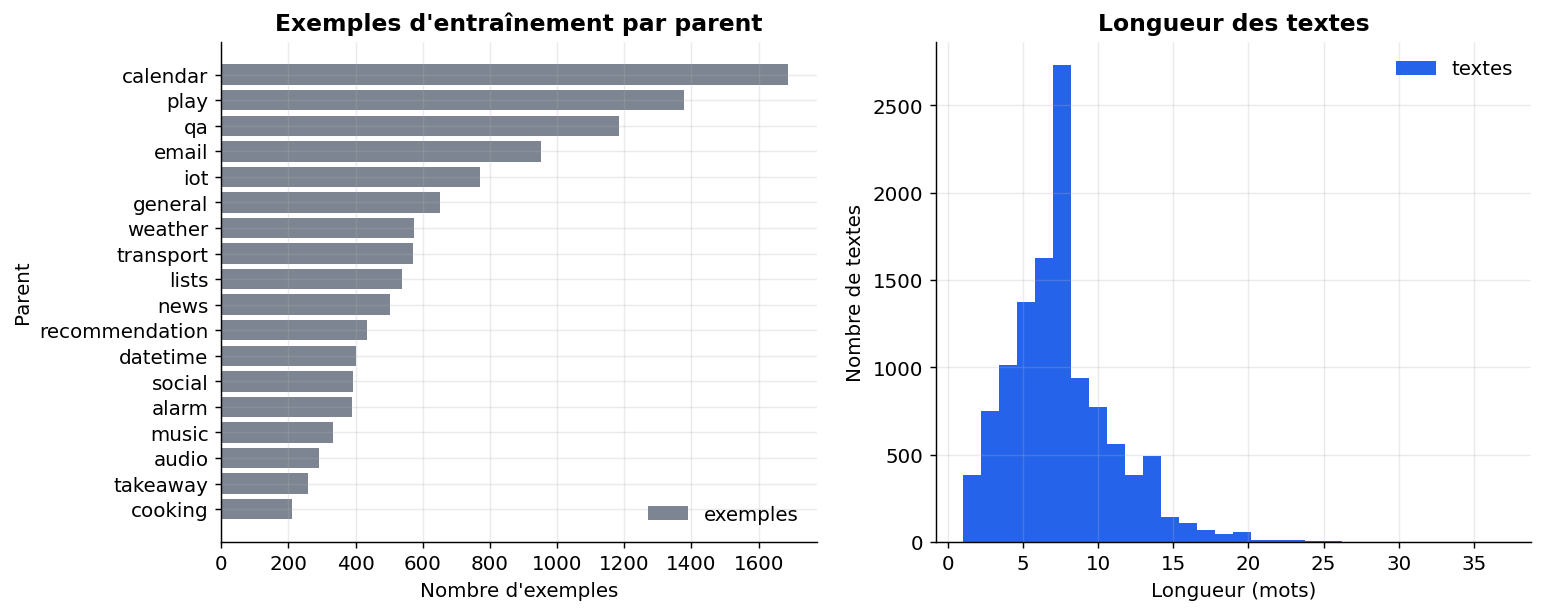

*Figure — À gauche, nombre d'énoncés d'entraînement par scénario (parent) : la répartition est inégale. À droite, longueur des énoncés en mots : textes très courts.*

,feuille,description
0,alarm_query,Demande du domaine « alarmes » ; l'utilisateur...
1,alarm_remove,Demande du domaine « alarmes » ; l'utilisateur...
2,alarm_set,Demande du domaine « alarmes » ; l'utilisateur...
3,audio_volume_down,Demande du domaine « volume audio » ; l'utilis...


In [12]:
def plot_data_overview(frame: pd.DataFrame, name: str, caption: str) -> None:
    """Deux panneaux : exemples d'entraînement par parent, et longueur des textes en mots."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    counts = frame["parent"].value_counts().sort_values()
    axes[0].barh(counts.index.astype(str), counts.values, color=COLORS["reference"], label="exemples")
    axes[0].set(title="Exemples d'entraînement par parent", xlabel="Nombre d'exemples", ylabel="Parent")
    axes[0].legend()
    axes[1].hist(frame["text"].str.split().str.len(), bins=30, color=COLORS["new"], label="textes")
    axes[1].set(title="Longueur des textes", xlabel="Longueur (mots)", ylabel="Nombre de textes")
    axes[1].legend()
    save_figure(fig, name, caption)


if PHASE == "public":
    plot_data_overview(train_full, "public_data_overview",
                       "À gauche, nombre d'énoncés d'entraînement par scénario (parent) : la répartition est "
                       "inégale. À droite, longueur des énoncés en mots : textes très courts.")
    preview(train_full)
    display(pd.DataFrame({"feuille": list(path_descriptions)[:4],
                          "description": list(path_descriptions.values())[:4]}))

### Colonnes attendues et jeu factice

Les données internes ont cinq colonnes : le texte, le **motif** (parent), le **sous-motif** (feuille), une courte description du sous-motif et la date de réception. Pour vérifier le code sans aucune donnée réelle, on fabrique un **jeu factice** plausible :
- une petite taxonomie de services financiers (carte de paiement, compte, virement…) ;
- des effectifs inégaux, des dates étalées sur un an, des formules d'ouverture et de clôture variées.

Les réglages de la section (découpage temporel, appels au LLM interne) sont regroupés ici.

In [13]:
N_FAKE_ROWS = 900          # lignes du jeu factice : ~60 par sous-motif, assez pour tous les budgets
TRAIN_SHARE = 0.7          # 70 % des messages les plus anciens pour l'entraînement
VALIDATION_SHARE = 0.1     # 10 % suivants pour choisir l'époque ; les 20 % récents pour le test
LLM_MAX_TOKENS = 200       # une ou deux phrases de description suffisent
LLM_EXAMPLES_PER_PATH = 3  # messages d'entraînement montrés au LLM pour ancrer la description
DESCRIPTION_SCHEMA = {     # sortie structurée demandée au LLM interne
    "type": "object", "properties": {"description": {"type": "string"}},
    "required": ["description"], "additionalProperties": False,
}

FAKE_TAXONOMY = {  # motif → sous-motif → (description courte, formulations types)
    "Carte de paiement": {
        "Opposition": ("Blocage d'une carte perdue ou volée", ("J'ai perdu ma carte, il faut la bloquer tout de suite.", "On m'a volé ma carte de paiement hier soir, faites opposition.")),
        "Plafond": ("Modification du plafond de paiement ou de retrait", ("Je voudrais augmenter le plafond de ma carte pour un achat de {amount} euros.", "Mon paiement de {amount} euros est refusé, le plafond de la carte est atteint.")),
        "Carte non reçue": ("Carte commandée mais pas encore reçue", ("J'attends toujours ma nouvelle carte commandée il y a trois semaines.", "Ma carte de remplacement n'est jamais arrivée par la poste.")),
    },
    "Compte": {
        "Relevé": ("Demande de relevé ou d'attestation", ("Pouvez-vous m'envoyer le relevé de compte du mois dernier ?", "J'ai besoin d'une attestation de solde pour un dossier.")),
        "Clôture": ("Fermeture du compte", ("Je souhaite clôturer mon compte courant.", "Comment fermer mon compte et récupérer les {amount} euros restants ?")),
        "Coordonnées": ("Changement d'adresse ou de téléphone", ("J'ai déménagé, merci de mettre à jour mon adresse sur le compte.", "Mon numéro de téléphone a changé, je ne reçois plus les codes.")),
    },
    "Virement": {
        "Virement non reçu": ("Virement attendu qui n'apparaît pas", ("Le virement de {amount} euros n'est toujours pas arrivé sur mon compte.", "On m'a fait un virement lundi mais je ne vois rien.")),
        "Bénéficiaire": ("Ajout ou suppression d'un bénéficiaire", ("Je n'arrive pas à ajouter un nouveau bénéficiaire pour mes virements.", "Comment supprimer un bénéficiaire de ma liste ?")),
        "Annulation de virement": ("Annulation d'un virement émis", ("J'ai fait un virement de {amount} euros par erreur, pouvez-vous l'annuler ?", "Je veux annuler le virement programmé pour demain.")),
    },
    "Prélèvement": {
        "Contestation": ("Prélèvement non autorisé contesté", ("Un prélèvement de {amount} euros que je ne connais pas est passé.", "Je conteste ce prélèvement, je n'ai jamais signé de mandat.")),
        "Mandat": ("Mise en place ou révocation d'un mandat", ("Je veux révoquer le mandat de prélèvement de mon ancien fournisseur.", "Comment autoriser un nouveau prélèvement mensuel ?")),
        "Rejet": ("Prélèvement rejeté faute de provision", ("Mon prélèvement de {amount} euros a été rejeté, pourquoi ?", "Le prélèvement du loyer a été refusé alors que le compte était approvisionné.")),
    },
    "Frais": {
        "Frais contestés": ("Contestation de frais prélevés", ("On m'a prélevé {amount} euros de frais sans explication.", "Je demande le remboursement de ces frais d'incident.")),
        "Grille tarifaire": ("Question sur les tarifs", ("Combien coûte un retrait à l'étranger avec ma carte ?", "Où trouver la liste des tarifs pour la tenue de compte ?")),
    },
}

### Générateur du jeu factice

`make_fake_data(n)` tire `n` messages selon des poids inégaux, ce qui crée quelques sous-motifs rares. Il insère des montants aléatoires et date chaque message dans l'année. Aucune donnée réelle n'est utilisée. `PRIVATE_COLUMNS` reprend exactement les colonnes attendues des données internes.

In [14]:
PRIVATE_COLUMNS = {
    "text": "Texte du message ou e-mail anonymisé",
    "reason": "Motif (niveau 1)",
    "sub_reason": "Sous-motif (niveau 2)",
    "sub_reason_description": "Description courte du sous-motif pour l'alignement",
    "received_at": "Date de réception",
}
OPENINGS = ["Bonjour,", "Bonsoir,", "Madame, Monsieur,", "", "Re bonjour,"]
CLOSINGS = ["Merci d'avance.", "Cordialement.", "Pouvez-vous m'aider ?", "", "C'est assez urgent."]


def make_fake_data(n: int) -> pd.DataFrame:
    """Jeu factice plausible (aucune donnée réelle) : effectifs inégaux, dates étalées sur un an."""
    rng = np.random.default_rng(SEED)
    leaves = [(reason, sub_reason, description, phrases)
              for reason, subs in FAKE_TAXONOMY.items() for sub_reason, (description, phrases) in subs.items()]
    weights = np.linspace(1.0, 2.5, len(leaves))  # quelques sous-motifs plus rares que d'autres
    choices = rng.choice(len(leaves), size=n, p=weights / weights.sum())
    start = pd.Timestamp("2025-01-01")
    rows = []
    for leaf_index in choices:
        reason, sub_reason, description, phrases = leaves[leaf_index]
        body = str(rng.choice(phrases)).format(amount=int(rng.integers(10, 3000)))
        parts = [str(rng.choice(OPENINGS)), body, str(rng.choice(CLOSINGS))]
        rows.append({"text": " ".join(part for part in parts if part), "reason": reason,
                     "sub_reason": sub_reason, "sub_reason_description": description,
                     "received_at": start + pd.Timedelta(minutes=int(rng.integers(0, 365 * 24 * 60)))})
    return pd.DataFrame(rows)

### Nettoyage et découpage temporel

Le jeu est relu depuis un fichier, et les types peuvent y être perdus. On les **reconvertit donc explicitement** : textes en chaînes, dates par `pd.to_datetime`. La feuille est nommée « motif > sous-motif », pour que deux motifs puissent avoir un sous-motif homonyme sans casser l'arbre. Le **découpage est temporel** : on apprend sur le passé et on teste sur la période la plus récente, comme en production.

In [15]:
def prepare_private_frame(raw: pd.DataFrame) -> pd.DataFrame:
    """Convertit les types, construit parent / feuille, retire les lignes incomplètes et trie par date."""
    missing = set(PRIVATE_COLUMNS) - set(raw.columns)
    assert not missing, f"Colonnes manquantes : {sorted(missing)}"
    frame = pd.DataFrame({
        "text": raw["text"].fillna("").astype(str).str.strip(),
        "parent": raw["reason"].fillna("").astype(str).str.strip(),
        "sub_reason": raw["sub_reason"].fillna("").astype(str).str.strip(),
        "sub_reason_description": raw["sub_reason_description"].fillna("").astype(str).str.strip(),
        "received_at": pd.to_datetime(raw["received_at"], errors="coerce", utc=True),
    })
    # la feuille porte son parent : un sous-motif homonyme sous deux motifs reste deux feuilles
    frame["leaf"] = frame["parent"] + " > " + frame["sub_reason"]
    complete = ((frame["text"].str.len() > 0) & (frame["parent"].str.len() > 0)
                & (frame["sub_reason"].str.len() > 0) & frame["received_at"].notna())
    homonyms = int(frame[complete].groupby("sub_reason")["parent"].nunique().gt(1).sum())
    print(f"Lignes complètes retenues : {int(complete.sum())} / {len(frame)} ; "
          f"sous-motifs présents sous plusieurs motifs : {homonyms}")
    return frame[complete].sort_values("received_at", kind="stable").reset_index(drop=True)


def temporal_split(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Découpage temporel : les plus anciens pour l'entraînement, les plus récents pour le test."""
    n_rows = len(frame)
    train_end = int(n_rows * TRAIN_SHARE)
    validation_end = int(n_rows * (TRAIN_SHARE + VALIDATION_SHARE))
    return (frame.iloc[:train_end].copy(), frame.iloc[train_end:validation_end].copy(),
            frame.iloc[validation_end:].copy())

### Chargement des données internes

On charge le jeu (le jeu factice lors de la vérification), on le découpe, puis on applique **les mêmes fonctions** qu'en phase publique : arbre, classes rares, échantillonnage du test, figure de synthèse. Seuls des effectifs et des agrégats s'affichent, jamais de texte brut.

In [16]:
if PHASE == "private":
    private_frame = prepare_private_frame(load_private_data(PRIVATE_COLUMNS, make_fake_data, n_fake=N_FAKE_ROWS))
    train_full, validation_raw, test_raw = temporal_split(private_frame)
    tree, validation, test = finalize_splits(train_full, validation_raw, test_raw, SEED)
    rare_leaves = find_rare_leaves(train_full)
    dataset_info = {"name": "données internes", "config": "motif > sous-motif",
                    "split": "test (période la plus récente)"}
    print(f"Entraînement jusqu'au {train_full['received_at'].max():%Y-%m-%d} ; "
          f"test à partir du {test_raw['received_at'].min():%Y-%m-%d}")
    print(f"{len(tree['parent_names'])} motifs, {len(tree['leaf_names'])} sous-motifs, "
          f"{len(rare_leaves)} sous-motifs rares")
    display(split_summary({"train": train_full, "validation": validation, "test": test}))
    plot_data_overview(train_full, "private_data_overview",
                       "À gauche, nombre de messages d'entraînement par motif ; à droite, longueur "
                       "des messages en mots (agrégats seulement).")
    preview(train_full)

### Descriptions de chemins par le LLM interne

Comme dans la source, une phrase décrit chaque chemin motif → sous-motif. Elle est rédigée par le **LLM interne** (`llm_chat`, configuré par l'environnement), **jamais par une API externe**. Le LLM reçoit le chemin, la description courte du sous-motif et trois messages d'entraînement.
- Une réponse illisible compte comme **erreur** : elle est remplacée par un gabarit et son taux est rapporté.
- Écart à la source : on produit une description **par chemin**, et non par couple texte-chemin. Le nombre d'appels reste ainsi borné par le nombre de sous-motifs.

In [17]:
def fallback_description(parent: str, sub_reason: str, short_description: str) -> str:
    """Description par gabarit, utilisée si le LLM ne rend pas de réponse lisible."""
    return f"Message relevant du motif « {parent} », sous-motif « {sub_reason} » : {short_description}"


def generate_path_description(parent: str, sub_reason: str, short_description: str,
                              examples: list[str]) -> str | None:
    """Demande au LLM interne une phrase reliant ce chemin aux messages ; None si la réponse est illisible."""
    shown = "\n".join(f"- {text[:300]}" for text in examples)
    messages = [
        {"role": "system", "content": "Tu décris des catégories de messages clients dans les services "
         "financiers. Réponds en français, en une ou deux phrases, sans aucune donnée personnelle."},
        {"role": "user", "content": f"Chemin : {parent} → {sub_reason}\nDéfinition : {short_description}\n"
         f"Exemples :\n{shown}\nExplique ce qui rattache un message à ce chemin plutôt qu'à un sous-motif voisin."},
    ]
    try:
        answer = llm_chat(messages, schema=DESCRIPTION_SCHEMA, temperature=0.0, max_tokens=LLM_MAX_TOKENS)
    except Exception as error:  # service indisponible : compté comme erreur, sans arrêter l'expérience
        print(f"Appel au LLM en échec : {type(error).__name__}")
        return None
    text = str(answer.get("description", "")).strip() if isinstance(answer, dict) else ""
    return text or None


def build_llm_descriptions(frame: pd.DataFrame, tree: dict, seed: int) -> tuple[dict[str, str], float]:
    """Une description par chemin ; rend aussi le taux de réponses illisibles."""
    descriptions, failures = {}, 0
    for leaf in tree["leaf_names"]:
        rows = frame[frame["leaf"] == leaf]
        filled = rows.loc[rows["sub_reason_description"].str.len() > 0, "sub_reason_description"]
        short_description = filled.mode().iloc[0] if len(filled) else rows["sub_reason"].iloc[0]
        examples = rows["text"].sample(n=min(LLM_EXAMPLES_PER_PATH, len(rows)), random_state=seed).tolist()
        parent, sub_reason = tree["leaf_to_parent"][leaf], rows["sub_reason"].iloc[0]
        generated = generate_path_description(parent, sub_reason, short_description, examples)
        if generated is None:
            failures += 1
            generated = fallback_description(parent, sub_reason, short_description)
        descriptions[leaf] = generated
    return descriptions, failures / len(tree["leaf_names"])

### Génération des descriptions

On appelle le LLM une fois par sous-motif, puis on affiche des agrégats : nombre de chemins décrits, taux de réponses illisibles et longueur médiane des descriptions.

In [18]:
if PHASE == "private":
    path_descriptions, DESCRIPTION_ERROR_RATE = build_llm_descriptions(train_full, tree, SEED)
    DESCRIPTION_SOURCE = "LLM interne (une description par chemin)"
    description_words = pd.Series([len(text.split()) for text in path_descriptions.values()])
    display(pd.DataFrame([{
        "chemins décrits": len(path_descriptions),
        "réponses illisibles (%)": round(100 * DESCRIPTION_ERROR_RATE, 1),
        "mots par description (médiane)": float(description_words.median()),
    }]))

## 3. L'approche de référence

### La référence : CamemBERT + BCE sur les nœuds

- **Encodeur** : CamemBERT-base, qui résume le texte par le vecteur du premier jeton `<s>`.
- **Tête multi-étiquettes** : une sortie par nœud (les parents, puis les feuilles). Chaque texte a deux cibles à 1 : son parent et sa feuille.
- **Perte BCE** (entropie croisée binaire) : $-[y\log p + (1-y)\log(1-p)]$ pour chaque nœud, soit une décision oui/non par étiquette.
- **Prédiction** : la feuille de plus forte probabilité. Le parent prédit, c'est-à-dire le parent de plus forte probabilité, sert à mesurer la cohérence.

Les réglages ci-dessous sont **communs aux trois variantes**. Deux choix complètent la recette standard, toujours à l'identique pour toutes : un taux d'apprentissage plus fort pour les couches neuves, et un nombre minimal de pas à l'échelle complète, pour que les petits budgets ne soient pas sous-entraînés.

In [19]:
MODEL_ID = "almanach/camembert-base"  # encodeur français étudié (licence MIT)
DEVICE = device()                     # « cuda », « mps » ou « cpu »
USE_FP16 = DEVICE == "cuda"           # précision mixte seulement sur GPU NVIDIA
EPOCHS = by_scale(reduced=1, full=5)  # nombre minimal d'époques
MIN_TRAIN_STEPS = by_scale(reduced=0, full=300)  # pas minimum : 5 ex./feuille ne fait que ~10 pas par époque
BATCH_SIZE = by_scale(reduced=16, full=32)       # lots d'entraînement
EVAL_BATCH_SIZE = 64            # lots d'inférence
LEARNING_RATE = 5e-5            # encodeur pré-entraîné : taux classique de fine-tuning
HEAD_LEARNING_RATE = 1e-3       # couches neuves (tête, projections, vecteurs de chemins)
WEIGHT_DECAY = 0.01             # régularisation d'AdamW
WARMUP_SHARE = 0.1              # 10 % des pas en préchauffage linéaire du taux
GRADIENT_CLIP = 1.0             # écrêtage de la norme des gradients (stabilité)
INITIAL_BIAS = -4.0             # sigmoïde(-4) ≈ 2 % : a priori faible pour chaque nœud
PROJECTION_DIM = 256            # espace des pertes contrastives (inutilisé par la référence)
MAX_LENGTH_CEILING = 256        # plafond absolu en tokens, imposé par la mémoire
COVERAGE_QUANTILE = 0.98        # le plafond laisse entiers 98 % des textes de chaque feuille
LATENCY_SAMPLES = by_scale(reduced=30, full=100)  # textes chronométrés un par un

### Longueur des entrées en tokens

Un texte coupé peut perdre l'indice qui permet de le classer. Avant tout entraînement, on mesure donc la longueur en **tokens** (les morceaux de mots que voit le modèle) du train et du test. On choisit le plus petit plafond, multiple de 8, qui laisse entiers **98 % des textes de chaque feuille**, et on affiche la part coupée. Les descriptions de chemins ont leur propre plafond.

In [20]:
tokenizer = AutoTokenizer.from_pretrained(model_path(MODEL_ID))


def token_lengths(texts) -> np.ndarray:
    """Nombre de tokens de chaque texte, jetons spéciaux compris."""
    return np.array([len(ids) for ids in tokenizer(list(texts))["input_ids"]])


def round_up_to_8(value: float) -> int:
    """Arrondit au multiple de 8 supérieur (tailles plus efficaces sur GPU)."""
    return int(8 * math.ceil(float(value) / 8))


length_frame = pd.concat([train_full[["text", "leaf"]], test[["text", "leaf"]]], ignore_index=True)
length_frame["tokens"] = token_lengths(length_frame["text"])
per_leaf_quantile = length_frame.groupby("leaf")["tokens"].quantile(COVERAGE_QUANTILE)
MAX_LENGTH = min(MAX_LENGTH_CEILING, round_up_to_8(per_leaf_quantile.max()))
truncated_share = (length_frame["tokens"] > MAX_LENGTH).groupby(length_frame["leaf"]).mean()
description_tokens = token_lengths(path_descriptions.values())
DESCRIPTION_MAX_LENGTH = min(MAX_LENGTH_CEILING, round_up_to_8(description_tokens.max()))
display(pd.DataFrame([{
    "tokens (médiane)": int(length_frame["tokens"].median()),
    "tokens (p95)": int(length_frame["tokens"].quantile(0.95)),
    "tokens (max)": int(length_frame["tokens"].max()),
    "plafond textes": MAX_LENGTH,
    "coupés, global (%)": round(100 * float((length_frame["tokens"] > MAX_LENGTH).mean()), 2),
    "coupés, pire feuille (%)": round(100 * float(truncated_share.max()), 2),
    "plafond descriptions": DESCRIPTION_MAX_LENGTH,
}]))
if truncated_share.max() > 0.05:
    print(f"Attention : plus de 5 % de textes coupés dans une feuille. Le plafond de {MAX_LENGTH_CEILING} "
          "tokens est imposé par la mémoire ; les résultats de ces feuilles peuvent en dépendre.")

,tokens (médiane),tokens (p95),tokens (max),plafond textes,"coupés, global (%)","coupés, pire feuille (%)",plafond descriptions
0,11,20,91,32,0.19,1.5,32


### Encodage des étiquettes

Chaque nœud reçoit un indice : d'abord les parents, puis les feuilles. `node_targets` construit la cible **multi-étiquettes**, c'est-à-dire un vecteur de 0 avec un 1 sur le parent et un 1 sur la feuille du texte. `tokenize` complète chaque lot jusqu'au texte le plus long (*padding*) et l'envoie sur le matériel de calcul.

In [21]:
N_PARENTS = len(tree["parent_names"])   # nœuds de niveau 1
N_LEAVES = len(tree["leaf_names"])      # nœuds de niveau 2 : les classes à prédire
N_NODES = N_PARENTS + N_LEAVES          # sorties de la tête : parents puis feuilles
LEAF_PARENT = tree["leaf_parent_index"]
LEAF_POSITION = {name: i for i, name in enumerate(tree["leaf_names"])}
PARENT_POSITION = {name: i for i, name in enumerate(tree["parent_names"])}
RARE_LEAF_IDX = np.array([LEAF_POSITION[leaf] for leaf in rare_leaves], dtype=int)


def encode_split(frame: pd.DataFrame) -> dict:
    """Textes et indices (feuille, parent) d'un split, prêts pour l'entraînement ou l'évaluation."""
    return {"texts": frame["text"].tolist(),
            "leaf_idx": frame["leaf"].map(LEAF_POSITION).to_numpy(dtype=int),
            "parent_idx": frame["parent"].map(PARENT_POSITION).to_numpy(dtype=int)}


def tokenize(texts: list[str], max_length: int) -> dict:
    """Tokenise un lot (complété au plus long du lot) et le place sur le matériel de calcul."""
    encoded = tokenizer(list(texts), padding=True, truncation=True, max_length=max_length,
                        return_tensors="pt")
    return {name: tensor.to(DEVICE) for name, tensor in encoded.items()}


def node_targets(leaf_idx: np.ndarray, parent_idx: np.ndarray) -> torch.Tensor:
    """Cibles multi-étiquettes : 1 pour le parent et pour la feuille de chaque texte, 0 ailleurs."""
    targets = torch.zeros(len(leaf_idx), N_NODES, device=DEVICE)
    rows = torch.arange(len(leaf_idx), device=DEVICE)
    targets[rows, torch.as_tensor(parent_idx, device=DEVICE)] = 1.0
    targets[rows, N_PARENTS + torch.as_tensor(leaf_idx, device=DEVICE)] = 1.0
    return targets


validation_data, test_data = encode_split(validation), encode_split(test)

### Les métriques, définies une fois pour tout le notebook

- **Macro-F1 des feuilles** : moyenne des $F_1 = 2PR/(P+R)$ calculés feuille par feuille. Chaque classe compte autant, même rare. C'est aussi le critère de choix de l'époque sur la validation.
- **Micro-F1** : calculé sur l'ensemble des décisions. En mono-étiquette, il égale l'exactitude.
- **Macro-F1 des feuilles rares** : même calcul, limité aux feuilles rares. La valeur est absente (NaN) si aucune n'est dans l'échantillon.

In [22]:
def leaf_macro_f1(y_true, y_pred) -> float:
    """Macro-F1 des feuilles : moyenne des F1 sur les feuilles présentes dans la vérité."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return float(f1_score(y_true, y_pred, labels=np.unique(y_true), average="macro", zero_division=0))


def leaf_micro_f1(y_true, y_pred) -> float:
    """Micro-F1 des feuilles (en mono-étiquette, égal à l'exactitude)."""
    return float(f1_score(np.asarray(y_true), np.asarray(y_pred), average="micro", zero_division=0))


def accuracy(y_true, y_pred) -> float:
    """Part des positions où les deux tableaux coïncident."""
    return float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))


def rare_class_macro_f1(y_true, y_pred) -> float:
    """Macro-F1 limité aux feuilles rares présentes dans la vérité (NaN s'il n'y en a aucune)."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    labels = np.intersect1d(RARE_LEAF_IDX, np.unique(y_true))
    if len(labels) == 0:
        return float("nan")
    return float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0))

### Le modèle

Une seule classe sert aux trois variantes, pour garantir une comparaison à architecture égale. Elle contient aussi les couches propres à la nouvelle approche : deux **projections** et un **vecteur appris par chemin**. La référence ne les entraîne jamais, et **aucune variante ne s'en sert à l'inférence**. Le biais initial négatif de la tête part d'une probabilité a priori faible pour chaque nœud, ce qui évite de gaspiller les premiers pas.

In [23]:
class HierarchicalTextClassifier(nn.Module):
    """CamemBERT + tête multi-étiquettes sur les nœuds de l'arbre.

    `text_projection`, `description_projection` et `path_vectors` ne servent qu'aux pertes
    auxiliaires d'entraînement : l'inférence n'utilise que l'encodeur et `node_head`.
    """

    def __init__(self, n_nodes: int, n_paths: int):
        """Charge l'encodeur et crée la tête sur les nœuds, les deux projections et un vecteur par chemin.

        Args : `n_nodes` = nombre de sorties de la tête (parents + feuilles) ;
        `n_paths` = nombre de chemins racine → feuille (un par feuille).
        """
        super().__init__()
        # pas de couche de pooling : on lit directement le vecteur du jeton <s>
        self.encoder = AutoModel.from_pretrained(model_path(MODEL_ID), add_pooling_layer=False)
        hidden_size = self.encoder.config.hidden_size
        self.dropout = nn.Dropout(0.1)
        self.node_head = nn.Linear(hidden_size, n_nodes)
        nn.init.constant_(self.node_head.bias, INITIAL_BIAS)
        self.text_projection = nn.Linear(hidden_size, PROJECTION_DIM)
        self.description_projection = nn.Linear(hidden_size, PROJECTION_DIM)
        self.path_vectors = nn.Parameter(torch.randn(n_paths, PROJECTION_DIM) * 0.02)

    def encode(self, batch: dict) -> torch.Tensor:
        """Vecteur du premier jeton (<s>), résumé du texte."""
        return self.encoder(**batch).last_hidden_state[:, 0]

    def forward(self, batch: dict) -> tuple[torch.Tensor, torch.Tensor]:
        """Logits des nœuds et représentation du texte."""
        pooled = self.encode(batch)
        return self.node_head(self.dropout(pooled)), pooled

### Vérification sur un exemple réel

Avant d'entraîner, on charge le modèle et on le passe sur **un vrai texte du train**. On vérifie par `assert` qu'il s'agit bien d'un encodeur CamemBERT et que la tête a le bon nombre de sorties. On relève ce qui tourne réellement (classe, attention, précision, versions), et ce relevé reste dans le notebook publié.

In [24]:
set_seed(SEED)
probe = HierarchicalTextClassifier(N_NODES, N_LEAVES).to(DEVICE).eval()
with torch.no_grad():
    probe_logits, _ = probe(tokenize(train_full["text"].iloc[:1].tolist(), MAX_LENGTH))
assert probe.encoder.config.model_type == "camembert", "L'encodeur chargé n'est pas celui étudié"
assert tuple(probe_logits.shape) == (1, N_NODES), "Nombre de sorties inattendu"
display(pd.Series({
    "modèle évalué": MODEL_ID,
    "classe chargée": type(probe.encoder).__name__,
    "paramètres de l'encodeur (M)": round(sum(p.numel() for p in probe.encoder.parameters()) / 1e6, 1),
    "attention": str(getattr(probe.encoder.config, "_attn_implementation", "inconnue")),
    "matériel": DEVICE,
    "précision mixte fp16": USE_FP16,
    "sorties de la tête": N_NODES,
    "torch": torch.__version__,
    "transformers": transformers.__version__,
}, name="relevé d'exécution").to_frame())
del probe, probe_logits
gc.collect()

,relevé d'exécution
modèle évalué,almanach/camembert-base
classe chargée,CamembertModel
paramètres de l'encodeur (M),110.0
attention,sdpa
matériel,cuda
précision mixte fp16,True
sorties de la tête,78
torch,2.14.1+cu130
transformers,5.22.1


10297

### Inférence

L'inférence est **la même pour toutes les variantes** : l'encodeur et la tête produisent une probabilité par nœud (fonction sigmoïde). La feuille prédite est celle de plus forte probabilité, et de même pour le parent. Sur GPU, la **précision mixte** (fp16) accélère le calcul.

In [25]:
def autocast_context():
    """Précision mixte fp16 sur GPU NVIDIA, calcul en précision normale ailleurs."""
    if USE_FP16:
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return contextlib.nullcontext()


@torch.no_grad()
def predict_node_probabilities(model: nn.Module, texts: list[str]) -> np.ndarray:
    """Probabilités (sigmoïde) de chaque nœud, par lots ; seuls l'encodeur et la tête servent."""
    model.eval()
    outputs = []
    for start in range(0, len(texts), EVAL_BATCH_SIZE):
        with autocast_context():
            logits, _ = model(tokenize(texts[start:start + EVAL_BATCH_SIZE], MAX_LENGTH))
        outputs.append(torch.sigmoid(logits.float()).cpu().numpy())
    return np.concatenate(outputs)


def decode_predictions(probabilities: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Feuille prédite (argmax des feuilles) et parent prédit (argmax des parents)."""
    return probabilities[:, N_PARENTS:].argmax(axis=1), probabilities[:, :N_PARENTS].argmax(axis=1)

### Une époque d'entraînement

Pour chaque lot, on calcule la perte BCE sur les nœuds, à laquelle s'ajoute une **perte auxiliaire** quand la variante en a une (paramètre `extra_loss`). La référence passe `None`. Le reste de la boucle est identique pour tous : AdamW, préchauffage linéaire du taux, écrêtage des gradients et précision mixte sur GPU.

In [26]:
def build_optimizer(model: nn.Module, total_steps: int):
    """AdamW à deux taux (encodeur pré-entraîné / couches neuves) et préchauffage linéaire."""
    encoder_ids = {id(parameter) for parameter in model.encoder.parameters()}
    new_parameters = [p for p in model.parameters() if id(p) not in encoder_ids]
    optimizer = torch.optim.AdamW(
        [{"params": list(model.encoder.parameters()), "lr": LEARNING_RATE},
         {"params": new_parameters, "lr": HEAD_LEARNING_RATE}], weight_decay=WEIGHT_DECAY)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_SHARE * total_steps), total_steps)
    return optimizer, scheduler


def train_one_epoch(model, data, optimizer, scheduler, scaler, generator, extra_loss=None) -> float:
    """Une passe sur le train : BCE sur les nœuds + perte auxiliaire éventuelle ; rend la perte moyenne."""
    model.train()
    losses = []
    for indices in torch.randperm(len(data["texts"]), generator=generator).split(BATCH_SIZE):
        rows = indices.numpy()
        batch = tokenize([data["texts"][i] for i in rows], MAX_LENGTH)
        leaf = torch.as_tensor(data["leaf_idx"][rows], device=DEVICE)
        with autocast_context():
            node_logits, pooled = model(batch)
            loss = F.binary_cross_entropy_with_logits(
                node_logits.float(), node_targets(data["leaf_idx"][rows], data["parent_idx"][rows]))
            if extra_loss is not None:
                loss = loss + extra_loss(model, pooled, node_logits, leaf)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)  # l'écrêtage doit voir les vrais gradients
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        losses.append(float(loss.detach()))
    return float(np.mean(losses))

### Entraînement complet et choix de l'époque

À la fin de chaque époque, on mesure le macro-F1 des feuilles sur la **validation** et on garde les poids de la meilleure époque. Cette règle est **la même pour toutes les variantes** et le test n'y intervient jamais. Le nombre d'époques vaut au moins `EPOCHS`, et davantage si nécessaire pour atteindre `MIN_TRAIN_STEPS` pas.

In [27]:
def train_model(train_frame: pd.DataFrame, extra_loss=None) -> tuple[nn.Module, pd.DataFrame]:
    """Entraîne une variante et garde l'époque au meilleur macro-F1 de validation.

    Rend le modèle (poids de la meilleure époque) et l'historique par époque.
    """
    set_seed(SEED)
    data = encode_split(train_frame)
    model = HierarchicalTextClassifier(N_NODES, N_LEAVES).to(DEVICE)
    steps_per_epoch = math.ceil(len(data["texts"]) / BATCH_SIZE)
    epochs = max(EPOCHS, math.ceil(MIN_TRAIN_STEPS / steps_per_epoch))
    optimizer, scheduler = build_optimizer(model, epochs * steps_per_epoch)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_FP16)
    generator = torch.Generator().manual_seed(SEED)  # ordre des lots reproductible
    history, best_score, best_state = [], -1.0, None
    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(model, data, optimizer, scheduler, scaler, generator, extra_loss)
        assert math.isfinite(train_loss), "Perte non finie : entraînement divergent"
        leaf_pred, _ = decode_predictions(predict_node_probabilities(model, validation_data["texts"]))
        score = leaf_macro_f1(validation_data["leaf_idx"], leaf_pred)
        history.append({"epoch": epoch, "train_loss": train_loss, "validation_leaf_macro_f1": score})
        if score > best_score:
            best_score = score
            best_state = {name: value.detach().to("cpu", copy=True) for name, value in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

### Un entraînement par budget, latences comprises

`run_variant` entraîne une variante pour chaque budget d'étiquettes et prédit le test. Elle chronomètre aussi l'inférence **texte par texte**, après un échauffement, puis libère la mémoire avant l'entraînement suivant. On ne garde que les prédictions, l'historique et les latences, et jamais trois modèles en mémoire à la fois.

In [28]:
def budget_key(budget: int | None) -> str:
    """Clé courte d'un budget : « 5 », « 20 » ou « all »."""
    return "all" if budget is None else str(budget)


def budget_label(budget: int | None) -> str:
    """Libellé lisible d'un budget."""
    return "train complet" if budget is None else f"{budget} ex. par feuille"


def release_memory() -> None:
    """Libère la mémoire entre deux entraînements (indispensable sur GPU)."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def measure_latency(model: nn.Module, texts: list[str]) -> list[float]:
    """Latence d'inférence texte par texte, en millisecondes, après un échauffement."""
    predict_node_probabilities(model, texts[:2])
    durations: list[float] = []
    for text in texts:
        with timer(durations):
            predict_node_probabilities(model, [text])
    return durations

### Boucle sur les budgets

Chaque budget est tiré avec la même graine pour toutes les variantes. Les trois approches voient donc **exactement les mêmes exemples d'entraînement**, et l'écart mesuré ne vient que de la perte.

In [29]:
def run_variant(label: str, extra_loss=None) -> dict:
    """Entraîne puis évalue une variante pour chaque budget ; garde prédictions de test, historique, latences."""
    runs = {}
    for budget in BUDGETS:
        started = time.perf_counter()
        train_budget = sample_budget(train_full, budget, SEED)
        model, history = train_model(train_budget, extra_loss)
        leaf_pred, parent_pred = decode_predictions(predict_node_probabilities(model, test_data["texts"]))
        best = history.loc[history["validation_leaf_macro_f1"].idxmax()]
        run = {"budget": budget, "n_train": len(train_budget), "leaf_pred": leaf_pred,
               "parent_pred": parent_pred, "history": history, "best_epoch": int(best["epoch"]),
               "epochs": len(history),
               "latencies_ms": measure_latency(model, test_data["texts"][:LATENCY_SAMPLES]),
               "seconds": time.perf_counter() - started}
        runs[budget_key(budget)] = run
        print(f"[{label}] {budget_label(budget)} : {run['n_train']} exemples, époque retenue "
              f"{run['best_epoch']}/{run['epochs']}, macro-F1 validation "
              f"{best['validation_leaf_macro_f1']:.3f}, {run['seconds']:.0f} s")
        del model
        release_memory()
    return runs


def runs_overview(runs: dict) -> pd.DataFrame:
    """Tableau résumé des entraînements d'une variante (une ligne par budget)."""
    return pd.DataFrame([{
        "budget": budget_label(run["budget"]), "exemples": run["n_train"],
        "époque retenue": f"{run['best_epoch']}/{run['epochs']}",
        "macro-F1 validation": round(float(run["history"]["validation_leaf_macro_f1"].max()), 4),
        "durée (s)": round(run["seconds"], 1)} for run in runs.values()])

### Entraînement de la référence

On entraîne la référence en BCE seule, sans perte auxiliaire, pour chaque budget.

In [30]:
reference_runs = run_variant("BCE", extra_loss=None)
display(runs_overview(reference_runs))

[BCE] 5 ex. par feuille : 299 exemples, époque retenue 29/30, macro-F1 validation 0.578, 58 s


[BCE] 20 ex. par feuille : 1176 exemples, époque retenue 9/9, macro-F1 validation 0.667, 42 s


[BCE] train complet : 11514 exemples, époque retenue 5/5, macro-F1 validation 0.816, 173 s


,budget,exemples,époque retenue,macro-F1 validation,durée (s)
0,5 ex. par feuille,299,29/30,0.5783,57.5
1,20 ex. par feuille,1176,9/9,0.6671,42.0
2,train complet,11514,5/5,0.8159,172.6


## 4. La nouvelle approche

### La nouvelle approche : PathSimNCE + alignement de descriptions

On reprend les deux objectifs de la section méthode de la source, qui s'ajoutent à la BCE **à l'entraînement seulement** :

$$\mathcal{L} = \mathcal{L}_{BCE} + 0{,}5\,\mathcal{L}_{PathSim} + 0{,}5\,\mathcal{L}_{desc}$$

**Proximité de deux chemins.** $s(p,q) = \dfrac{\text{profondeur de leur ancêtre commun le plus bas}}{\text{profondeur maximale}}$. Avec deux niveaux, on obtient 1 pour le même chemin, 0,5 pour deux feuilles sœurs et 0 sinon.

Écarts à la source, à garder en tête :
- l'arbre a deux niveaux et chaque texte une seule feuille, donc **un seul chemin correct** par texte ;
- la forme exacte de $s$, la pondération des voisins (0,2) et celle des négatifs durs (×2) sont des choix de cette réimplémentation ;
- descriptions : **gabarit** en phase publique, **LLM interne** en phase privée, une par chemin, alors que la source utilise GPT-4o, une par couple texte-chemin.

In [31]:
PATHSIM_WEIGHT = 0.5        # poids de PathSimNCE dans la perte totale
DESCRIPTION_WEIGHT = 0.5    # poids de l'alignement de descriptions
TEMPERATURE = 0.1           # température des softmax contrastives (plus bas = plus sélectif)
NEIGHBOR_WEIGHT = 0.2       # cible d'un chemin voisin, relative au bon chemin, × sa proximité s
HARD_NEGATIVE_WEIGHT = 2.0  # poids d'un voisin mal classé dans le dénominateur (négatif dur)


def leaf_paths(tree: dict) -> list[tuple[str, ...]]:
    """Chemin racine → feuille de chaque feuille, sous forme de tuple (parent, feuille)."""
    return [(tree["leaf_to_parent"][leaf], leaf) for leaf in tree["leaf_names"]]


def path_similarity_matrix(paths: list[tuple[str, ...]]) -> np.ndarray:
    """s(p, q) = profondeur de l'ancêtre commun le plus bas / profondeur maximale des deux chemins."""
    similarity = np.zeros((len(paths), len(paths)))
    for i, first in enumerate(paths):
        for j, second in enumerate(paths):
            common = 0
            while common < min(len(first), len(second)) and first[common] == second[common]:
                common += 1
            similarity[i, j] = common / max(len(first), len(second))
    return similarity


PATH_SIMILARITY = torch.tensor(path_similarity_matrix(leaf_paths(tree)), dtype=torch.float32, device=DEVICE)
identity = torch.eye(N_LEAVES, dtype=torch.bool, device=DEVICE)
# cible brute : 1 pour le bon chemin, NEIGHBOR_WEIGHT × s pour les autres (0 hors du même parent)
SOFT_TARGETS = torch.where(identity, torch.ones_like(PATH_SIMILARITY), NEIGHBOR_WEIGHT * PATH_SIMILARITY)
gold_share = (SOFT_TARGETS.diagonal() / SOFT_TARGETS.sum(dim=1)).cpu().numpy()
print(f"Part du bon chemin dans la cible : moyenne {gold_share.mean():.2f}, minimum {gold_share.min():.2f}")

Part du bon chemin dans la cible : moyenne 0.77, minimum 0.56


### PathSimNCE

La perte est une **InfoNCE** (retrouver le bon chemin parmi tous, via une softmax sur les similarités cosinus $c_j$ entre le texte et chaque vecteur de chemin) avec une **cible adoucie** $t$ :

$$\mathcal{L}_{PathSim} = -\sum_j t_j \log \frac{w_j\, e^{c_j/\tau}}{\sum_k w_k\, e^{c_k/\tau}}$$

- $t_j$ vaut 1 pour le bon chemin et $0{,}2 \times s$ pour un chemin voisin, puis la cible est normalisée.
- Un voisin que la tête BCE note **au-dessus** du bon chemin est un **négatif dur** : sa cible passe à 0 et son poids $w_j$ passe à 2, ce qui le repousse plus fort. Pour tous les autres chemins, $w_j = 1$.

In [32]:
def pathsim_loss(model, pooled: torch.Tensor, node_logits: torch.Tensor, leaf: torch.Tensor) -> torch.Tensor:
    """PathSimNCE : InfoNCE texte ↔ vecteurs de chemins, cibles adoucies par la proximité dans l'arbre.

    Les chemins voisins que la tête place au-dessus du bon deviennent des négatifs durs :
    cible remise à zéro et poids accru dans le dénominateur de la softmax.
    """
    text_vectors = F.normalize(model.text_projection(pooled).float(), dim=-1)
    path_vectors = F.normalize(model.path_vectors.float(), dim=-1)
    logits = text_vectors @ path_vectors.T / TEMPERATURE
    with torch.no_grad():  # le choix des négatifs durs ne reçoit pas de gradient
        leaf_scores = node_logits[:, N_PARENTS:].float()
        gold_scores = leaf_scores.gather(1, leaf[:, None])
        similarity = PATH_SIMILARITY[leaf]
        confused = (leaf_scores > gold_scores) & (similarity > 0) & (similarity < 1)
        targets = SOFT_TARGETS[leaf].masked_fill(confused, 0.0)
        targets = targets / targets.sum(dim=1, keepdim=True)
    logits = logits + confused.float() * math.log(HARD_NEGATIVE_WEIGHT)
    return -(targets * F.log_softmax(logits.float(), dim=-1)).sum(dim=1).mean()

### Alignement de descriptions

L'encodeur partagé encode les descriptions des chemins présents dans le lot. Chaque texte doit retrouver **la description de son chemin** parmi celles des autres chemins du lot, avec une perte contrastive (entropie croisée sur les similarités). `make_extra_loss` assemble ensuite les pertes auxiliaires avec leurs poids, dans une fonction `extra_loss` que la boucle d'entraînement appelle à chaque lot.

In [33]:
DESCRIPTION_TEXTS = [path_descriptions[leaf] for leaf in tree["leaf_names"]]  # une par chemin, même ordre


def description_alignment_loss(model, pooled: torch.Tensor, leaf: torch.Tensor) -> torch.Tensor:
    """Contrastif texte ↔ description du bon chemin, contre les descriptions des autres chemins du lot."""
    unique_leaves, positions = torch.unique(leaf, return_inverse=True)
    batch = tokenize([DESCRIPTION_TEXTS[i] for i in unique_leaves.tolist()], DESCRIPTION_MAX_LENGTH)
    description_vectors = F.normalize(model.description_projection(model.encode(batch)).float(), dim=-1)
    text_vectors = F.normalize(model.text_projection(pooled).float(), dim=-1)
    logits = text_vectors @ description_vectors.T / TEMPERATURE
    return F.cross_entropy(logits.float(), positions)


def make_extra_loss(pathsim_weight: float, description_weight: float):
    """Assemble les pertes auxiliaires d'entraînement ; l'inférence ne les utilise jamais."""
    def extra_loss(model, pooled, node_logits, leaf):
        """Perte auxiliaire d'un lot : PathSimNCE pondérée, plus l'alignement de descriptions si son poids est non nul.

        Args : modèle, représentations des textes, logits des nœuds, indices des vraies feuilles.
        Retour : un scalaire à ajouter à la BCE.
        """
        total = pathsim_weight * pathsim_loss(model, pooled, node_logits, leaf)
        if description_weight > 0:
            total = total + description_weight * description_alignment_loss(model, pooled, leaf)
        return total
    return extra_loss

### Contrôle de PathSimNCE sur des cas faciles

Avant d'entraîner, on vérifie le sens de la perte. Un texte dont le vecteur coïncide avec **son** chemin doit coûter moins cher qu'un texte aligné sur un chemin **d'un autre parent**. Un `assert` arrête l'expérience si ce n'est pas le cas.

In [34]:
set_seed(SEED)
dummy_model = SimpleNamespace(text_projection=nn.Identity(),
                              path_vectors=torch.randn(N_LEAVES, PROJECTION_DIM, device=DEVICE))
check_leaves = torch.arange(min(8, N_LEAVES), device=DEVICE)
# pour chaque feuille, une feuille d'un autre parent (cas « mauvais chemin, éloigné dans l'arbre »)
other_parent = [int(np.flatnonzero(LEAF_PARENT != LEAF_PARENT[i])[0]) for i in check_leaves.tolist()]
neutral_logits = torch.zeros(len(check_leaves), N_NODES, device=DEVICE)  # aucun négatif dur ici
with torch.no_grad():
    loss_aligned = pathsim_loss(dummy_model, dummy_model.path_vectors[check_leaves], neutral_logits, check_leaves)
    loss_misaligned = pathsim_loss(dummy_model, dummy_model.path_vectors[other_parent], neutral_logits, check_leaves)
display(pd.DataFrame([{"perte, texte aligné sur son chemin": round(float(loss_aligned), 3),
                       "perte, texte aligné sur un chemin éloigné": round(float(loss_misaligned), 3)}]))
assert loss_aligned < loss_misaligned, "PathSimNCE ne favorise pas le bon chemin"
del dummy_model

,"perte, texte aligné sur son chemin","perte, texte aligné sur un chemin éloigné"
0,2.074,10.137


### Entraînement des deux variantes

On entraîne deux variantes, avec les mêmes budgets, la même graine et la même règle de choix d'époque que la référence :
1. **BCE + PathSimNCE**, pour isoler l'apport de la structure de l'arbre ;
2. **BCE + PathSimNCE + descriptions**, la méthode complète.

La seconde coûte un peu plus cher à l'entraînement, car il faut encoder les descriptions. L'inférence ne change pas.

In [35]:
pathsim_runs = run_variant("BCE + PathSimNCE", make_extra_loss(PATHSIM_WEIGHT, 0.0))
display(runs_overview(pathsim_runs))
description_runs = run_variant("BCE + PathSimNCE + descriptions",
                               make_extra_loss(PATHSIM_WEIGHT, DESCRIPTION_WEIGHT))
display(runs_overview(description_runs))

[BCE + PathSimNCE] 5 ex. par feuille : 299 exemples, époque retenue 25/30, macro-F1 validation 0.611, 58 s


/tmp/ipykernel_4246/2508968055.py:32: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[BCE + PathSimNCE] 20 ex. par feuille : 1176 exemples, époque retenue 9/9, macro-F1 validation 0.748, 43 s


[BCE + PathSimNCE] train complet : 11514 exemples, époque retenue 5/5, macro-F1 validation 0.826, 176 s


,budget,exemples,époque retenue,macro-F1 validation,durée (s)
0,5 ex. par feuille,299,25/30,0.6113,57.9
1,20 ex. par feuille,1176,9/9,0.7485,42.8
2,train complet,11514,5/5,0.8260,175.7


[BCE + PathSimNCE + descriptions] 5 ex. par feuille : 299 exemples, époque retenue 28/30, macro-F1 validation 0.642, 69 s


/tmp/ipykernel_4246/2508968055.py:32: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[BCE + PathSimNCE + descriptions] 20 ex. par feuille : 1176 exemples, époque retenue 9/9, macro-F1 validation 0.749, 56 s


[BCE + PathSimNCE + descriptions] train complet : 11514 exemples, époque retenue 4/5, macro-F1 validation 0.825, 243 s


,budget,exemples,époque retenue,macro-F1 validation,durée (s)
0,5 ex. par feuille,299,28/30,0.6420,69.5
1,20 ex. par feuille,1176,9/9,0.7493,55.6
2,train complet,11514,4/5,0.8248,242.9


## 5. Évaluation

### Mesures et intervalles de confiance

Toutes les variantes sont mesurées sur **les mêmes exemples de test**, avec cinq métriques :
- macro-F1 et micro-F1 des feuilles, macro-F1 des feuilles rares ;
- **exactitude du parent** : le parent prédit (argmax des parents) est-il le vrai ?
- **cohérence parent-enfant** : le parent prédit est-il bien le parent de la feuille prédite ?

Le **bootstrap** retire 1 000 fois des exemples au hasard, avec remise, pour voir à quel point chaque chiffre dépend de l'échantillon. On en tire un intervalle à 95 %. Une métrique sans objet, par exemple sans classe rare dans le test, vaut `None`.

In [36]:
N_BOOTSTRAP = 1000                 # rééchantillonnages du test
HYPOTHESIS_MACRO_F1_GAIN = 0.01    # gain attendu : +1 point de macro-F1 des feuilles
HYPOTHESIS_CONSISTENCY_GAIN = 0.02 # gain attendu : +2 points de cohérence parent-enfant
METRIC_LABELS = {"leaf_macro_f1": "Macro-F1 des feuilles", "leaf_micro_f1": "Micro-F1 des feuilles",
                 "parent_accuracy": "Exactitude du parent",
                 "hierarchical_consistency_rate": "Cohérence parent-enfant",
                 "rare_class_macro_f1": "Macro-F1 des feuilles rares"}
APPROACH_NAMES = {"bce": "CamemBERT + BCE (référence)", "pathsim": "BCE + PathSimNCE",
                  "pathsim_desc": "BCE + PathSimNCE + descriptions"}
VARIANT_COLORS = {"bce": COLORS["reference"], "pathsim": COLORS["accent"], "pathsim_desc": COLORS["new"]}
all_runs = {"bce": reference_runs, "pathsim": pathsim_runs, "pathsim_desc": description_runs}
MAIN_BUDGET_KEY = budget_key(BUDGETS[-1])  # budget rapporté dans les résultats : le plus grand


def metric_inputs(run: dict) -> dict[str, tuple]:
    """(vérité, prédiction, fonction) de chaque métrique ; la cohérence compare deux prédictions."""
    return {"leaf_macro_f1": (test_data["leaf_idx"], run["leaf_pred"], leaf_macro_f1),
            "leaf_micro_f1": (test_data["leaf_idx"], run["leaf_pred"], leaf_micro_f1),
            "parent_accuracy": (test_data["parent_idx"], run["parent_pred"], accuracy),
            "hierarchical_consistency_rate": (run["parent_pred"], LEAF_PARENT[run["leaf_pred"]], accuracy),
            "rare_class_macro_f1": (test_data["leaf_idx"], run["leaf_pred"], rare_class_macro_f1)}


def as_number(value) -> float | None:
    """Convertit en float Python ; None si la valeur est absente ou non finie (métrique sans objet)."""
    if value is None:
        return None
    value = float(value)
    return value if math.isfinite(value) else None


def compute_metrics(run: dict) -> tuple[dict, dict]:
    """Valeurs des cinq métriques et intervalles à 95 % par bootstrap."""
    metrics, ci95 = {}, {}
    for key, (truth, prediction, metric) in metric_inputs(run).items():
        value, low, high = bootstrap_ci(truth, prediction, metric, n=N_BOOTSTRAP, seed=SEED)
        metrics[key] = as_number(value)
        if None not in (metrics[key], as_number(low), as_number(high)):
            ci95[key] = [float(low), float(high)]
    return metrics, ci95

### Prédicteur trivial et tableau des résultats

Le **prédicteur trivial** répond toujours la feuille la plus fréquente du train. C'est le plancher : une approche dont l'intervalle de confiance ne le dépasse pas n'a rien appris d'exploitable. Les résultats enregistrés portent sur le **plus grand budget** de l'exécution, avec les latences d'inférence par texte (médiane p50 et 95e centile p95, en ms).

résultats enregistrés : results_public.json


,rôle,Macro-F1 des feuilles,Micro-F1 des feuilles,Exactitude du parent,Cohérence parent-enfant,Macro-F1 des feuilles rares,latence p50 (ms)
approche,,,,,,,
CamemBERT + BCE (référence),référence,0.8023 [0.7857 ; 0.8299],0.8753 [0.8631 ; 0.8877],0.9122 [0.9015 ; 0.9223],0.9876 [0.9835 ; 0.9913],0.5563 [0.5116 ; 0.6411],13.20
BCE + PathSimNCE,nouvelle,0.8355 [0.8144 ; 0.8642],0.882 [0.8695 ; 0.8937],0.923 [0.9126 ; 0.9321],0.9771 [0.9714 ; 0.9822],0.6684 [0.6011 ; 0.7681],12.94
BCE + PathSimNCE + descriptions,nouvelle,0.8248 [0.8035 ; 0.8564],0.88 [0.8675 ; 0.8921],0.918 [0.9069 ; 0.9277],0.9748 [0.9684 ; 0.9802],0.6333 [0.5606 ; 0.738],13.09


,leaf_macro_f1,leaf_micro_f1,parent_accuracy,hierarchical_consistency_rate,rare_class_macro_f1
prédicteur trivial (feuille majoritaire),0.0022,0.0703,0.1352,1.0,0.0


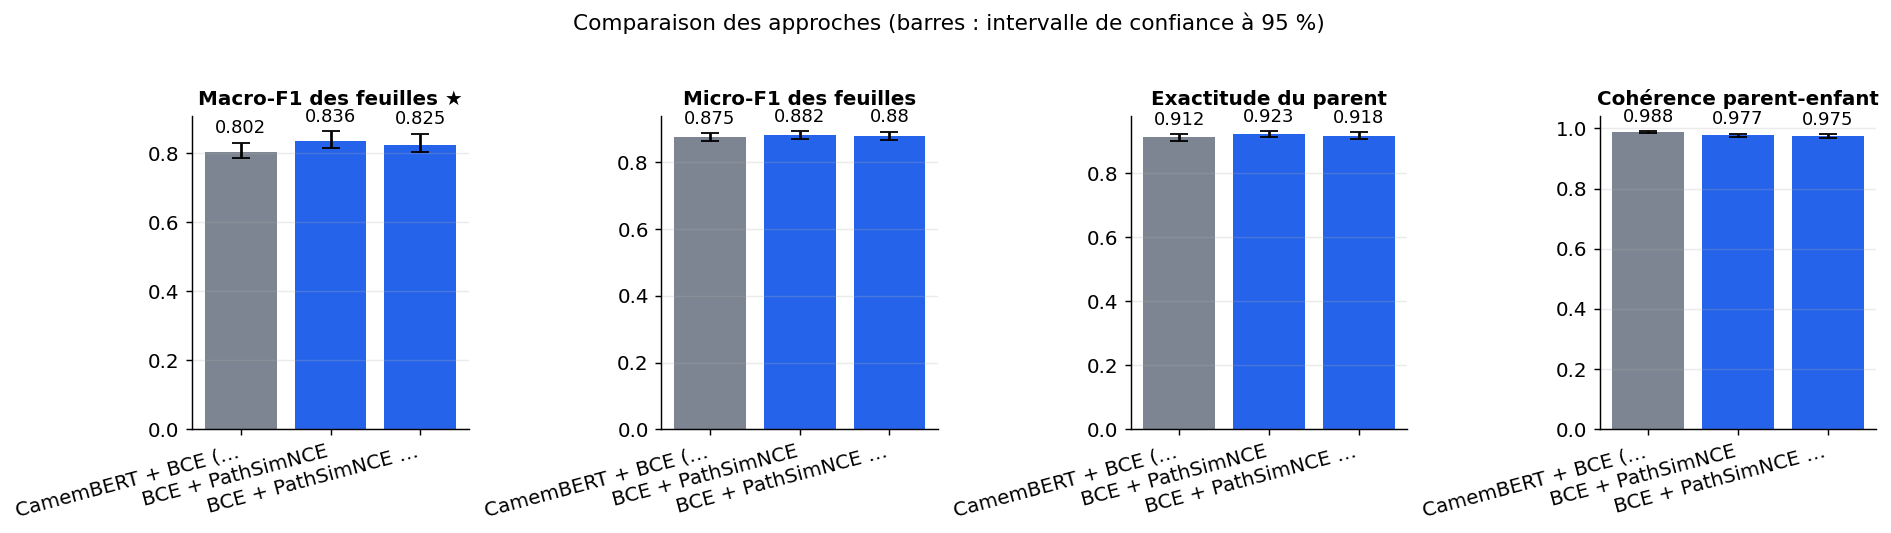

*Figure — Une barre par approche et par métrique, au plus grand budget ; les traits donnent l'intervalle de confiance à 95 % (bootstrap du test). Plus haut = mieux.*

In [37]:
majority_leaf = LEAF_POSITION[train_full["leaf"].value_counts().idxmax()]
trivial_run = {"leaf_pred": np.full(len(test), majority_leaf),
               "parent_pred": np.full(len(test), LEAF_PARENT[majority_leaf])}
trivial_metrics, _ = compute_metrics(trivial_run)
test_fingerprint = fingerprint(test["text"].tolist())

approaches = []
for key, runs in all_runs.items():
    run = runs[MAIN_BUDGET_KEY]
    metrics, ci95 = compute_metrics(run)
    latency = latency_stats(run["latencies_ms"])
    notes = (f"Budget : {budget_label(run['budget'])} ({run['n_train']} exemples) ; époque retenue "
             f"{run['best_epoch']}/{run['epochs']} ; inférence = encodeur + tête seuls ; "
             f"descriptions : {DESCRIPTION_SOURCE} ; empreinte du test : {test_fingerprint}")
    if key == "pathsim_desc" and DESCRIPTION_ERROR_RATE is not None:
        notes += f" ; réponses LLM illisibles : {DESCRIPTION_ERROR_RATE:.0%}"
    approaches.append({"name": APPROACH_NAMES[key], "role": "reference" if key == "bce" else "new",
                       "metrics": metrics, "ci95": ci95,
                       "latency_ms": {"p50": float(latency["p50"]), "p95": float(latency["p95"])},
                       "notes": notes})

results = save_results({
    "primary_metric": "leaf_macro_f1", "direction": "max", "metric_labels": METRIC_LABELS,
    "dataset": {**dataset_info, "n_examples": int(len(test))}, "approaches": approaches,
})
display(results_table(results))
display(pd.DataFrame([trivial_metrics], index=["prédicteur trivial (feuille majoritaire)"]).round(4))
plot_comparison(results, metrics=["leaf_macro_f1", "leaf_micro_f1", "parent_accuracy",
                                  "hierarchical_consistency_rate"],
                caption="Une barre par approche et par métrique, au plus grand budget ; les traits "
                        "donnent l'intervalle de confiance à 95 % (bootstrap du test). Plus haut = mieux.")

### Comparaison appariée, budget par budget

Deux intervalles qui se chevauchent ne prouvent rien. On utilise donc un **bootstrap apparié** : à chaque tirage, on prend **les mêmes exemples** pour la référence et la variante, et on calcule l'écart. Si l'intervalle de cet écart est tout entier au-dessus de 0, le gain ne vient pas du hasard de l'échantillon. On le fait pour le macro-F1 et pour la cohérence, à chaque budget.

In [38]:
def paired_bootstrap_delta(y_true, pred_reference, pred_new, metric, n: int = N_BOOTSTRAP,
                           seed: int = SEED) -> tuple[float, float, float, float]:
    """Écart apparié metric(nouvelle) − metric(référence) sur les mêmes rééchantillons.

    Rend l'écart observé, son intervalle à 95 % et la part des tirages où l'écart est ≤ 0.
    """
    y_true, pred_reference, pred_new = map(np.asarray, (y_true, pred_reference, pred_new))
    rng = np.random.default_rng(seed)
    deltas = np.empty(n)
    for draw in range(n):
        rows = rng.integers(0, len(y_true), len(y_true))
        deltas[draw] = metric(y_true[rows], pred_new[rows]) - metric(y_true[rows], pred_reference[rows])
    observed = metric(y_true, pred_new) - metric(y_true, pred_reference)
    low, high = np.percentile(deltas, [2.5, 97.5])
    return float(observed), float(low), float(high), float(np.mean(deltas <= 0))


def consistency_flags(run: dict) -> np.ndarray:
    """1 si le parent prédit est le parent de la feuille prédite, 0 sinon (par exemple de test)."""
    return (run["parent_pred"] == LEAF_PARENT[run["leaf_pred"]]).astype(int)


budget_rows = []
for key, runs in all_runs.items():
    for bkey, run in runs.items():
        value, low, high = bootstrap_ci(test_data["leaf_idx"], run["leaf_pred"], leaf_macro_f1,
                                        n=N_BOOTSTRAP, seed=SEED)
        budget_rows.append({"variant": key, "budget": bkey, "n_train": run["n_train"],
                            "leaf_macro_f1": float(value), "low": float(low), "high": float(high),
                            "consistency": float(consistency_flags(run).mean())})
budget_table = pd.DataFrame(budget_rows)
budget_table.to_csv(f"{OUTPUT_DIR}/budgets_{PHASE}.csv", index=False)
display(budget_table.round(4))

,variant,budget,n_train,leaf_macro_f1,low,high,consistency
0,bce,5,299,0.5742,0.5526,0.5955,0.9391
1,bce,20,1176,0.6732,0.6457,0.6988,0.9660
2,bce,all,11514,0.8023,0.7857,0.8299,0.9876
3,pathsim,5,299,0.5970,0.5761,0.6196,0.8914
4,pathsim,20,1176,0.7339,0.7133,0.7574,0.9375
5,pathsim,all,11514,0.8355,0.8144,0.8642,0.9771
6,pathsim_desc,5,299,0.6256,0.6036,0.6480,0.8954
7,pathsim_desc,20,1176,0.7322,0.7110,0.7570,0.9331
8,pathsim_desc,all,11514,0.8248,0.8035,0.8564,0.9748


### Verdict automatique

Pour chaque budget et chaque variante, le verdict suit des règles écrites à l'avance :
- **non concluant** si la référence ou la variante ne dépasse pas le prédicteur trivial (borne basse de l'intervalle) ;
- **hypothèse soutenue** si l'écart apparié de macro-F1 est significatif et atteint +1 point, et si la cohérence gagne au moins 2 points ;
- sinon gain net mais sous les seuils, dégradation nette, ou écart dans le bruit.

Avec une seule exécution par configuration, on reste prudent sur tout écart inférieur à 1 point.

In [39]:
def verdict(row: pd.Series) -> str:
    """Conclusion automatique à partir des écarts appariés et du plancher trivial."""
    if not row["eligible"]:
        return "non concluant : une approche ne dépasse pas le prédicteur trivial"
    if (row["delta_low"] > 0 and row["delta_macro_f1"] >= HYPOTHESIS_MACRO_F1_GAIN
            and row["delta_consistency"] >= HYPOTHESIS_CONSISTENCY_GAIN):
        return "hypothèse soutenue"
    if row["delta_low"] > 0:
        return "gain net, sous les seuils de l'hypothèse"
    if row["delta_high"] < 0:
        return "dégradation nette"
    return "non concluant : écart dans le bruit"


lower_bounds = budget_table.set_index(["variant", "budget"])["low"]
all_ones = np.ones(len(test), dtype=int)
comparison_rows = []
for key in ("pathsim", "pathsim_desc"):
    for bkey, run in all_runs[key].items():
        reference = all_runs["bce"][bkey]
        delta, low, high, p_value = paired_bootstrap_delta(
            test_data["leaf_idx"], reference["leaf_pred"], run["leaf_pred"], leaf_macro_f1)
        delta_consistency, consistency_low, consistency_high, _ = paired_bootstrap_delta(
            all_ones, consistency_flags(reference), consistency_flags(run), accuracy)
        eligible = min(lower_bounds[("bce", bkey)], lower_bounds[(key, bkey)]) > trivial_metrics["leaf_macro_f1"]
        comparison_rows.append({"variante": APPROACH_NAMES[key], "budget": bkey, "delta_macro_f1": delta,
                                "delta_low": low, "delta_high": high, "p_unilateral": p_value,
                                "delta_consistency": delta_consistency, "consistency_low": consistency_low,
                                "consistency_high": consistency_high, "eligible": bool(eligible)})
comparison = pd.DataFrame(comparison_rows)
comparison["verdict"] = comparison.apply(verdict, axis=1)
comparison.to_csv(f"{OUTPUT_DIR}/paired_comparison_{PHASE}.csv", index=False)
display(comparison.round(4))

,variante,budget,delta_macro_f1,delta_low,delta_high,p_unilateral,delta_consistency,consistency_low,consistency_high,eligible,verdict
0,BCE + PathSimNCE,5,0.0228,0.0057,0.0408,0.003,-0.0477,-0.0595,-0.0360,True,"gain net, sous les seuils de l'hypothèse"
1,BCE + PathSimNCE,20,0.0606,0.0368,0.0865,0.000,-0.0286,-0.0383,-0.0192,True,"gain net, sous les seuils de l'hypothèse"
2,BCE + PathSimNCE,all,0.0332,0.0160,0.0459,0.002,-0.0104,-0.0161,-0.0050,True,"gain net, sous les seuils de l'hypothèse"
3,BCE + PathSimNCE + descriptions,5,0.0514,0.0327,0.0709,0.000,-0.0437,-0.0558,-0.0316,True,"gain net, sous les seuils de l'hypothèse"
4,BCE + PathSimNCE + descriptions,20,0.0589,0.0368,0.0837,0.000,-0.0330,-0.0430,-0.0232,True,"gain net, sous les seuils de l'hypothèse"
5,BCE + PathSimNCE + descriptions,all,0.0225,0.0027,0.0368,0.005,-0.0128,-0.0188,-0.0071,True,"gain net, sous les seuils de l'hypothèse"


## 6. Analyse des résultats

### Le gain dépend-il du budget d'étiquettes ?

L'hypothèse prévoit un gain plus marqué quand les exemples sont rares. La figure trace le macro-F1 des feuilles de chaque variante pour chaque budget, avec son intervalle à 95 % et le niveau du prédicteur trivial en pointillés. À l'échelle réduite, un seul budget est mesuré.

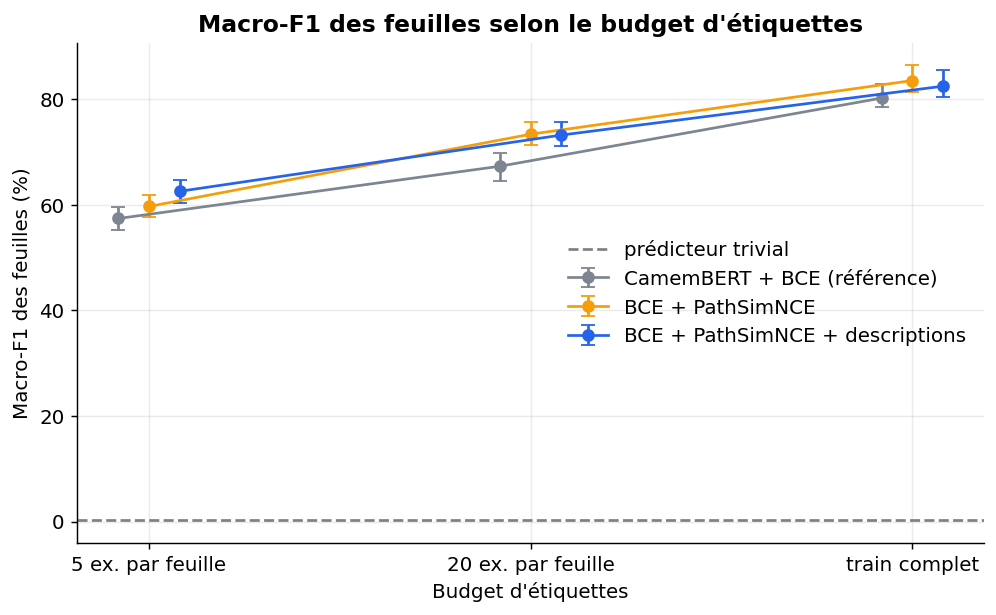

*Figure — Macro-F1 des feuilles (en %) de chaque variante selon le nombre d'exemples d'entraînement par feuille ; traits = intervalle à 95 % ; pointillés = prédicteur trivial. Plus haut = mieux.*

In [40]:
fig, ax = plt.subplots(figsize=(9, 5))
positions = np.arange(len(BUDGETS))
budget_order = [budget_key(budget) for budget in BUDGETS]
for offset, (key, color) in zip((-0.08, 0.0, 0.08), VARIANT_COLORS.items()):
    rows = budget_table[budget_table["variant"] == key].set_index("budget").loc[budget_order]
    values = rows["leaf_macro_f1"].to_numpy(dtype=float)
    errors = np.vstack([values - rows["low"].to_numpy(dtype=float), rows["high"].to_numpy(dtype=float) - values])
    ax.errorbar(positions + offset, 100 * values, yerr=100 * errors, marker="o", capsize=4,
                color=color, label=APPROACH_NAMES[key])
ax.axhline(100 * trivial_metrics["leaf_macro_f1"], linestyle="--", color="grey", label="prédicteur trivial")
ax.set_xticks(positions, [budget_label(budget) for budget in BUDGETS])
ax.set(title="Macro-F1 des feuilles selon le budget d'étiquettes", xlabel="Budget d'étiquettes",
       ylabel="Macro-F1 des feuilles (%)")
ax.legend()
save_figure(fig, "budget_curve",
            "Macro-F1 des feuilles (en %) de chaque variante selon le nombre d'exemples d'entraînement par "
            "feuille ; traits = intervalle à 95 % ; pointillés = prédicteur trivial. Plus haut = mieux.")

### Quel type d'erreur change ?

PathSimNCE vise précisément les confusions **entre feuilles sœurs**. On découpe donc les prédictions de test en trois parts :
- feuille correcte ;
- **erreur entre sœurs** : mauvaise feuille, mais sous le bon parent ;
- **erreur de parent** : la feuille prédite est sous un autre parent.

Si la méthode agit comme prévu, c'est surtout la part orange (erreurs entre sœurs) qui doit baisser.

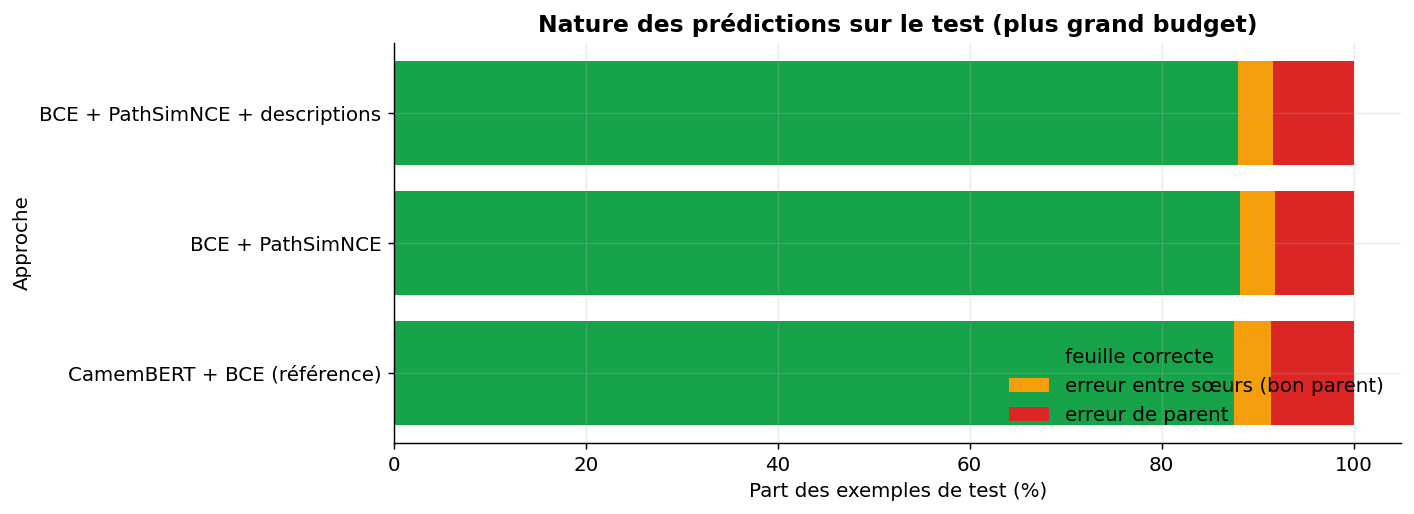

*Figure — Pour chaque approche, part des exemples de test bien classés, des erreurs entre feuilles sœurs (bon parent) et des erreurs de parent. Une méthode fondée sur l'arbre devrait réduire surtout la part du milieu.*

,feuille correcte,erreur entre sœurs (bon parent),erreur de parent
CamemBERT + BCE (référence),87.5,3.9,8.6
BCE + PathSimNCE,88.2,3.6,8.2
BCE + PathSimNCE + descriptions,88.0,3.6,8.4


In [41]:
def error_breakdown(run: dict) -> dict[str, float]:
    """Parts (en %) de feuilles correctes, d'erreurs entre sœurs et d'erreurs de parent."""
    correct = run["leaf_pred"] == test_data["leaf_idx"]
    same_parent = LEAF_PARENT[run["leaf_pred"]] == test_data["parent_idx"]
    return {"feuille correcte": 100 * correct.mean(),
            "erreur entre sœurs (bon parent)": 100 * (~correct & same_parent).mean(),
            "erreur de parent": 100 * (~same_parent).mean()}


breakdown = pd.DataFrame({APPROACH_NAMES[key]: error_breakdown(runs[MAIN_BUDGET_KEY])
                          for key, runs in all_runs.items()}).T
fig, ax = plt.subplots(figsize=(10, 4))
left = np.zeros(len(breakdown))
for column, color in zip(breakdown.columns, (COLORS["good"], COLORS["accent"], COLORS["bad"])):
    ax.barh(breakdown.index, breakdown[column], left=left, color=color, label=column)
    left += breakdown[column].to_numpy()
ax.set(title="Nature des prédictions sur le test (plus grand budget)",
       xlabel="Part des exemples de test (%)", ylabel="Approche")
ax.legend(loc="lower right")
save_figure(fig, "error_breakdown",
            "Pour chaque approche, part des exemples de test bien classés, des erreurs entre feuilles sœurs "
            "(bon parent) et des erreurs de parent. Une méthode fondée sur l'arbre devrait réduire surtout la part du milieu.")
display(breakdown.round(1))

### Quelles classes gagnent ou perdent ?

Un gain moyen peut cacher des pertes sur certaines classes. Pour chaque feuille présente dans le test, la figure montre l'écart de F1 entre la méthode complète et la référence, au plus grand budget. Une étoile marque les feuilles rares. Avec peu d'exemples de test par feuille, chaque barre est bruitée : on lit la **tendance d'ensemble**, pas une feuille isolée.

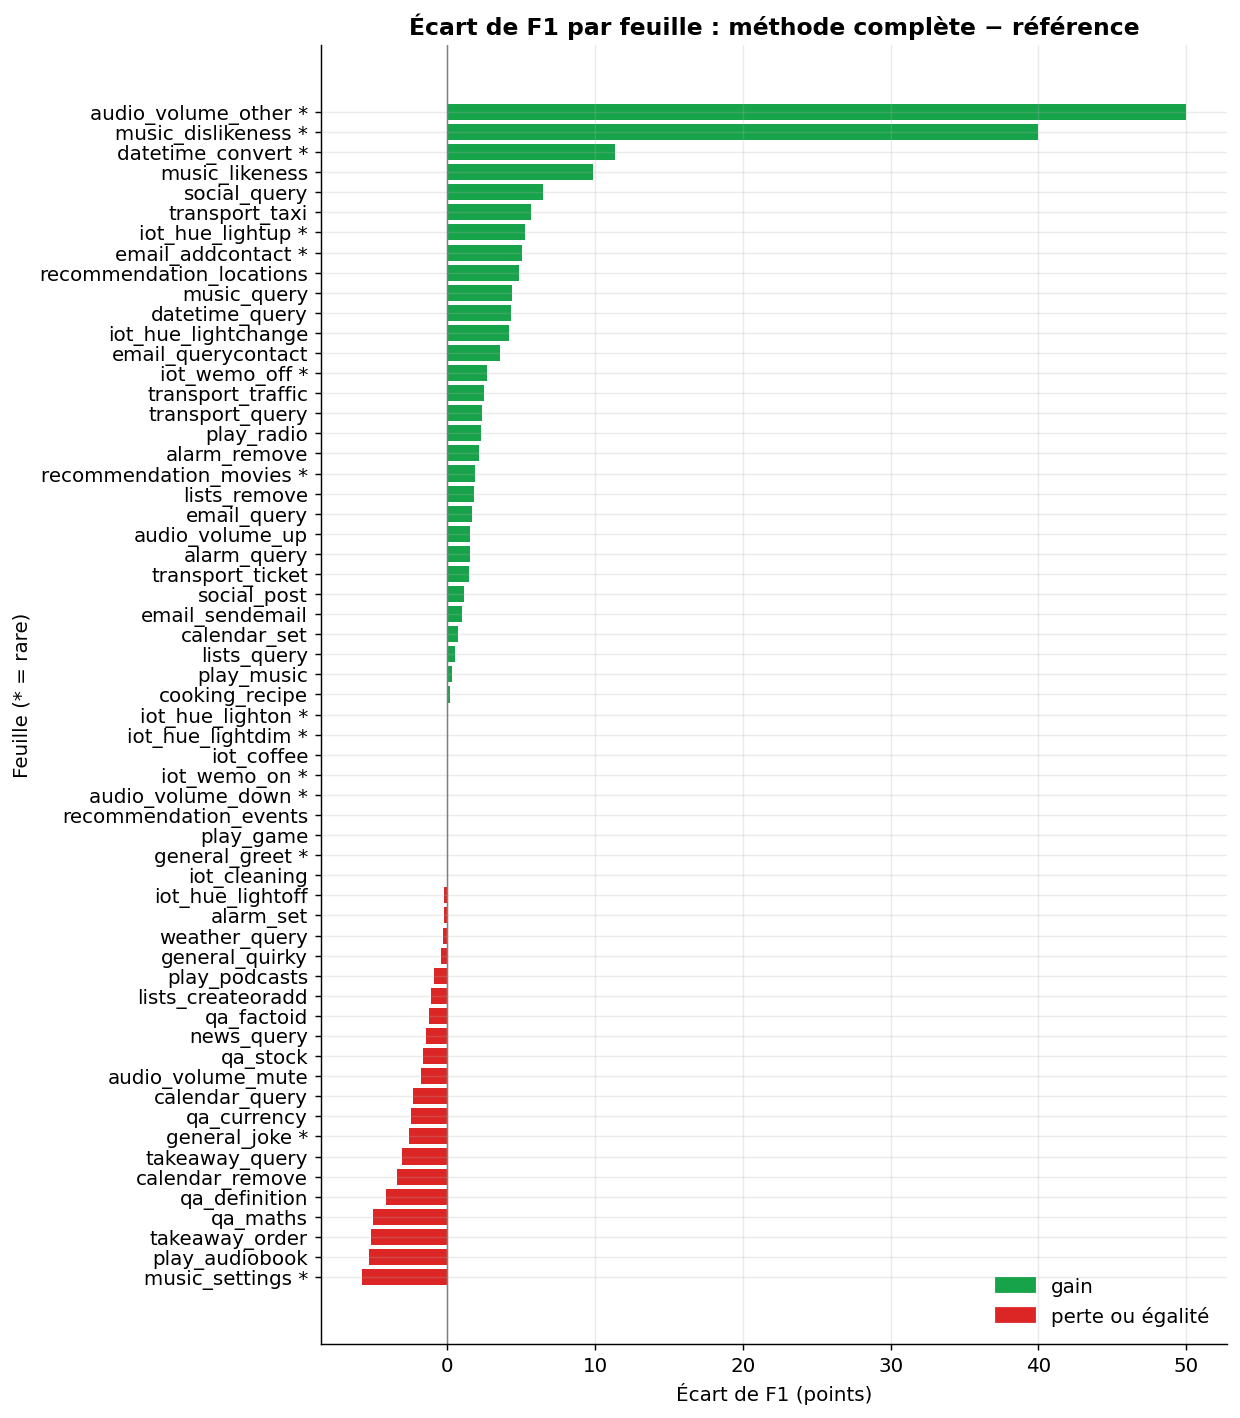

*Figure — Écart de F1 (en points) entre BCE + PathSimNCE + descriptions et la référence, feuille par feuille, au plus grand budget ; vert = gain, rouge = perte ou égalité ; * = feuille rare.*

Feuilles en gain : 30 ; en perte : 20 ; inchangées : 9


In [42]:
def per_leaf_f1(run: dict) -> np.ndarray:
    """F1 de chaque feuille sur le test (0 si la feuille n'est jamais prédite correctement)."""
    return f1_score(test_data["leaf_idx"], run["leaf_pred"], labels=np.arange(N_LEAVES),
                    average=None, zero_division=0)


present = np.unique(test_data["leaf_idx"])
gain = (per_leaf_f1(all_runs["pathsim_desc"][MAIN_BUDGET_KEY])
        - per_leaf_f1(all_runs["bce"][MAIN_BUDGET_KEY]))[present]
order = np.argsort(gain)
rare_set = set(RARE_LEAF_IDX.tolist())
names = [tree["leaf_names"][i] + (" *" if i in rare_set else "") for i in present[order]]
fig, ax = plt.subplots(figsize=(9, max(4, 0.22 * len(present))))
ax.barh(names, 100 * gain[order], color=[COLORS["good"] if g > 0 else COLORS["bad"] for g in gain[order]])
ax.axvline(0, color="grey", linewidth=0.8)
ax.set(title="Écart de F1 par feuille : méthode complète − référence",
       xlabel="Écart de F1 (points)", ylabel="Feuille (* = rare)")
ax.legend(handles=[Patch(color=COLORS["good"], label="gain"), Patch(color=COLORS["bad"], label="perte ou égalité")])
save_figure(fig, "per_leaf_gain",
            "Écart de F1 (en points) entre BCE + PathSimNCE + descriptions et la référence, feuille par feuille, "
            "au plus grand budget ; vert = gain, rouge = perte ou égalité ; * = feuille rare.")
print(f"Feuilles en gain : {int((gain > 0).sum())} ; en perte : {int((gain < 0).sum())} ; "
      f"inchangées : {int((gain == 0).sum())}")

### Exemples d'erreurs (phase publique seulement)

Voici quelques énoncés de test **corrigés** par la méthode complète, c'est-à-dire mal classés par la référence et bien classés par elle, puis quelques énoncés **dégradés**, dans le cas inverse. En phase privée, cette cellule n'affiche rien, car aucun texte interne n'est montré.

In [43]:
if PHASE == "public":
    reference_run = all_runs["bce"][MAIN_BUDGET_KEY]
    new_run = all_runs["pathsim_desc"][MAIN_BUDGET_KEY]
    truth = test_data["leaf_idx"]
    leaf_array = np.array(tree["leaf_names"])
    examples = pd.DataFrame({"texte": test["text"], "vraie feuille": leaf_array[truth],
                             "référence": leaf_array[reference_run["leaf_pred"]],
                             "méthode complète": leaf_array[new_run["leaf_pred"]]})
    fixed = examples[(reference_run["leaf_pred"] != truth) & (new_run["leaf_pred"] == truth)]
    broken = examples[(reference_run["leaf_pred"] == truth) & (new_run["leaf_pred"] != truth)]
    print(f"Énoncés corrigés : {len(fixed)} ; énoncés dégradés : {len(broken)}")
    display(fixed.head(5))
    display(broken.head(5))

Énoncés corrigés : 65 ; énoncés dégradés : 51


,texte,vraie feuille,référence,méthode complète
97,met le weekend,play_music,calendar_set,play_music
141,joue bilando,play_music,play_radio,play_music
155,l'avis de sauvegarde,music_likeness,general_quirky,music_likeness
184,où est le réglage du volume,audio_volume_other,audio_volume_up,audio_volume_other
217,s'il est cinq heures du matin à nice quelle he...,datetime_convert,datetime_query,datetime_convert


,texte,vraie feuille,référence,méthode complète
47,je peux à peine t'entendre,audio_volume_up,audio_volume_up,audio_volume_mute
221,parlez-moi de la politique extérieure de franç...,news_query,news_query,qa_factoid
290,changer le mode de la musique sur rock,music_settings,music_settings,play_music
314,je veux manger quelque chose d'épicé,takeaway_order,takeaway_order,cooking_recipe
346,apporte-moi le titre de la musique actuelle,music_query,music_query,play_music


### À retenir

- **Si** l'écart apparié de macro-F1 a un intervalle tout entier au-dessus de 0, les pertes par chemins apportent un gain réel sur ce jeu français. Le verdict affiché dit en plus s'il atteint le seuil de +1 point. Sinon, l'écart reste dans le bruit d'une seule exécution et rien ne permet de conclure.
- **Si** le gain est plus net à 5 exemples par feuille qu'au train complet, l'arbre sert surtout de **connaissance a priori** quand les annotations manquent. C'est le cas d'usage où l'adopter a le plus de sens.
- La **cohérence parent-enfant** n'est garantie par aucune variante (la source le reconnaît). Si elle reste sous 100 %, une contrainte au moment du routage, par exemple dériver le motif du sous-motif prédit, reste nécessaire.
- Le **coût d'inférence** est identique par construction (même encodeur et même tête) : les latences mesurées doivent se recouvrir. Le seul surcoût est à l'entraînement, plus la génération hors ligne des descriptions.
- **Si** une variante ne dépasse pas le prédicteur trivial (cas probable à l'échelle réduite : une époque, 5 exemples par feuille), le résultat est **non concluant** et doit être publié comme tel. Il faut alors refaire la mesure à l'échelle complète.

## 7. Bilan

> **Verdict** (confiance moyenne). À l'échelle complète (tout le jeu de test, 2 974 exemples, GPU T4), PathSimNCE améliore le macro-F1 des feuilles de la référence de +2,3 pts (5 exemples par feuille), +6,1 pts (20) et +3,3 pts (train complet), avec des intervalles appariés au-dessus de zéro. Les descriptions par gabarit n'ajoutent rien (+5,1, +5,9 et +2,2 pts). En revanche, la cohérence parent-enfant baisse partout (de -1,0 à -4,8 pts), donc l'hypothèse complète n'est pas soutenue, et le gain en exactitude globale reste faible (+0,7 pt au train complet). Une seule exécution par configuration et un jeu d'assistant vocal en français rendent l'ampleur des gains incertaine. Les chiffres ne se comparent pas à ceux de la source (autres jeux, autre tâche), et l'échelle réduite, sous le niveau du hasard, n'apporte aucune information.

*Échelle complète : 2974 exemples de test de `mteb/amazon_massive_intent` (GPU T4 (Google Colab), 19 min). La mécanique avait d'abord été validée à l'échelle réduite (300 exemples, CPU).*

| Approche | Macro-F1 des feuilles ★ ↑ | Micro-F1 des feuilles ↑ | Exactitude du parent ↑ | Cohérence parent-enfant ↑ | Macro-F1 des feuilles rares ↑ | Latence médiane (ms) ↓ |
|---|---|---|---|---|---|---|
| CamemBERT + BCE (référence) (référence) | 0,802 [0,786 ; 0,83] | 0,875 [0,863 ; 0,888] | 0,912 [0,901 ; 0,922] | **0,988 [0,984 ; 0,991]** | 0,556 [0,512 ; 0,641] | 13,2 |
| BCE + PathSimNCE (nouvelle approche) | **0,836 [0,814 ; 0,864]** | **0,882 [0,87 ; 0,894]** | **0,923 [0,913 ; 0,932]** | 0,977 [0,971 ; 0,982] | **0,668 [0,601 ; 0,768]** | 12,9 |
| BCE + PathSimNCE + descriptions (nouvelle approche) | 0,825 [0,804 ; 0,856] | 0,88 [0,868 ; 0,892] | 0,918 [0,907 ; 0,928] | 0,975 [0,968 ; 0,98] | 0,633 [0,561 ; 0,738] | 13,1 |

★ métrique principale · ↑ plus haut = meilleur · ↓ plus bas = meilleur · entre crochets : intervalle de confiance à 95 % (bootstrap) · en gras : la meilleure valeur.

**Réserves**

- Le gain de macro-F1 est réel sur ce jeu, mais il s'accompagne d'une baisse de la cohérence parent-enfant. L'hypothèse complète n'est donc pas confirmée, et un contrôle au routage devient plus nécessaire.
- Le sens du gain de PathSimNCE sur la référence est plausible, mais son ampleur (de +2 à +6 pts) reste incertaine. Rien ne permet de classer PathSimNCE seul et PathSimNCE avec descriptions.
- Sur l'ensemble des énoncés, l'amélioration est faible (moins d'un point d'exactitude). Le gain de macro-F1 est surtout porté par un petit nombre de classes, souvent rares, avec peu d'exemples de test.

**Limites**

- Une seule exécution par configuration : des écarts de moins de 1 point peuvent venir de la graine et non de la méthode.
- Le jeu public contient des énoncés d'assistant vocal courts, hors services financiers. L'arbre n'a que deux niveaux et une étiquette par texte, alors que la source utilise des hiérarchies plus profondes.
- En phase publique, les descriptions viennent d'un gabarit et non d'un LLM, ce qui défavorise la méthode d'après la source. En phase privée, on produit une description par chemin et non par couple texte-chemin.
- Certains détails de PathSimNCE (forme de la similarité, poids 0,2 des voisins, ×2 pour les négatifs durs) sont des choix de réimplémentation, non vérifiés contre le code d'origine.
- Aucune variante ne garantit la cohérence parent-enfant : en usage réel, une contrainte au moment du routage reste nécessaire.

**Échelle réduite : ce qui diffère de l'échelle complète**

- À l'échelle réduite, on garde le même modèle (CamemBERT-base) sur CPU. L'expérience se limite à un seul budget (5 exemples par feuille), une époque sans minimum de pas, des lots de 16, 120 exemples de validation, 300 exemples de test et 30 textes chronométrés pour la latence. À l'échelle complète : trois budgets, au moins 5 époques et 300 pas, des lots de 32, la validation et le test entiers.

**Améliorations possibles**

- La cohérence parent-enfant de la référence est déjà proche de 100 % au train complet. Une baisse y est donc mesurable, mais une hausse était impossible.
- Les scores aux petits budgets sont un peu optimistes pour toutes les variantes, car le choix de l'époque s'appuie sur beaucoup plus d'étiquettes que le budget annoncé. L'écart sur la référence pourrait se réduire avec un entraînement plus long.
- Cette expérience ne permet pas de juger l'apport des descriptions générées par un LLM. Elle teste seulement une version simplifiée, qui n'ajoute rien à PathSimNCE seul.

**Et ensuite ?** Rejouer le même protocole sur vos données : `PHASE = "private"`, `SCALE = "full"`, après avoir préparé le jeu et la configuration décrits dans le README (section « Sur vos données »).